# 第04章 矩阵的解剖：可填写Notebook

> 模板原件：第一次先复制到本章 `工作/` 目录，再改成本章实际组名，例如 `A1组-实验.ipynb`、`B2组-验证.ipynb`。原件保留；副本内同组链接也要同步改名。复用导入图时，将本章 `模板/图片/` 中的图复制到 `工作/图片/`，图片链接使用 `图片/文件名`。组号见本章 `README.md`，复制步骤见仓库根目录下 `教程/02-Notebook教材写作.md` 的“模板复制与命名”一节。

> A组任务：A1、A2各自独立完成本章四节的全部实验及配套正文、习题与解答；不预先分小节。完整初稿经B/C验证后，本章六组讨论各部分采用版本，再由D/E整合。

![三格漫画：矩阵体检发现敏感方向，右端微小扰动导致解明显变化，机器人质疑小残差。](图片/A-章节导入.svg)

*图04-1 · 给矩阵做一次体检。初始化概念示意；适用条件见下文，不作为实测结果。*

## 先看一幕：给矩阵做一次体检

求解器递来一份漂亮的报告：“残差几乎为零。”矩阵医生却拿起放大镜：如果输入轻轻动一下，解会不会跳很远？

**先猜，再验证：** 设 $A=\operatorname{diag}(1,10^{-10})$。仅把右端第二个分量增加 $10^{-10}$，解的第二个分量会改变多少？这与求解器报告的小残差是否矛盾？

**把故事翻译成数学：** 在这个对角例子中，解的第二分量增加1，二范数条件数为 $10^{10}$。图中体检对应对矩阵结构与扰动敏感性的分析；小残差和小解误差是不同主张，还要说明残差针对哪个右端计算。

> 状态：按64学时方案整理的可填写模板，正文、推导和各节完整实验待学生完成。已有漫画与起步代码是初始化材料，不代表学生成果。

**知识主题：** 线性方程组、特征值与SVD

**本章核心问题：** Ax=b如何高效求解？矩阵的本质结构是什么？

**只聚焦三个核心概念：** LU、CG、SVD

**先修知识：** 矩阵运算、内积、正定性与向量/矩阵范数

**课时：** 4节 × 2学时 = 8学时；全书八章共64学时。

### 本章四节安排

| 节 | 内容 | 学时 |
| --- | --- | --- |
| 4.1 | 直接法：LU与Cholesky | 2 |
| 4.2 | 迭代法：CG与预条件 | 2 |
| 4.3 | 特征值与SVD | 2 |
| 4.4 | AI关联：可微求解器、PCA、LoRA | 2 |

### 怎么填写本章

从第4.1节开始，把每处“【待填写】”替换为自己的讲解、推导和证据。正文负责连贯讲解；[A1组-实验.ipynb](A1组-实验.ipynb)按相同节号组织文字与代码，具体实现和实际输出以Notebook为准，正文引用相应小节并解释结果。两处共有的公式、参数和结论须同步。

每节保留“讲解—推导—实验—解释—讨论”，这些是填写栏，不是额外课时。小节内多个方法按提示控制深度；选读不扩大必修范围。

**已有起步实验的位置：** 4.3节。小残差与大解误差的对角矩阵示例用于联系奇异值和条件数；不代表已完成LU、CG或AI应用。

---


**Notebook填写方法：** 双击Markdown单元填写讲解；在Code单元写Python，Shift+Enter运行，Ctrl+S保存。带有“TODO/未完成”的单元只是位置提示，即使顺序执行没有报错，也不能算完成本节。


In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
print("Python:", sys.version.split()[0], "NumPy:", np.__version__)
print("这是可填写模板；有输出或无报错不代表各节已完成。")

Python: 3.12.10 NumPy: 1.26.4
这是可填写模板；有输出或无报错不代表各节已完成。


## 4.1 直接法：LU与Cholesky（2学时）

**本节目标：** 能按矩阵条件选择分解，并解释主元和三角求解。

### 概念讲解：把问题说明白

填写提示：带主元LU、对称正定矩阵的Cholesky、分解复用与多右端求解；避免显式求逆作为默认解法。

【待填写】用自己的语言讲解，定义符号、适用范围及先修概念；加入一个自己的例子。

### 关键推导：让结论有依据

推导任务：手算一个小矩阵的消元与回代，明确置换矩阵约定；写明Cholesky适用条件。

【待填写】已知条件 → 关键步骤 → 结论 → 条件不满足时的限制。引用定理时写明来源版本和位置。

### 实验设计：先预测，再运行

实验任务：用小型一般矩阵及正定矩阵求解，与可信库函数比较；加入需交换主元的例子。

| 要填写的项目 | 本组内容 |
| --- | --- |
| 要回答的问题与运行前预测 | 待填写 |
| 输入、参数、单位、数据来源与划分 | 待填写 |
| 独立参考解/基线及选择理由 | 待填写 |
| 误差指标、容差及其依据 | 待填写 |
| 环境、种子、设备与运行预算 | 待填写 |

【待填写】在本章Notebook的同号小节编写代码、亲自运行并保存输出。


In [2]:
# 4.1 输入与独立参考
from fractions import Fraction

cases = [
    {"name": "正文-LU", "kind": "LU",
     "K": np.array([[0., 2., 1.], [1., 1., 0.], [2., 0., 1.]]),
     "true_X": np.array([[1., 2.], [2., 0.], [-1., 1.]]),
     "rhs": np.array([3., 3., 1.]), "true_single": np.array([1., 2., -1.])},
    {"name": "正文-Cholesky", "kind": "Cholesky",
     "K": np.array([[4., 2., 2.], [2., 5., 1.], [2., 1., 3.]]),
     "true_X": np.array([[1., 2.], [2., 0.], [-1., 1.]]),
     "rhs": np.array([6., 11., 1.]), "true_single": np.array([1., 2., -1.])},
    {"name": "习题-LU", "kind": "LU",
     "K": np.array([[0., 2., 1.], [1., -1., 0.], [2., 1., 3.]]),
     "true_X": np.array([[1., -1.], [2., 0.], [-1., 2.]]),
     "rhs": np.array([0., 2., 7.]), "true_single": np.array([1., -1., 2.])},
    {"name": "习题-Cholesky", "kind": "Cholesky",
     "K": np.array([[4., 2., 0.], [2., 5., 2.], [0., 2., 5.]]),
     "true_X": np.array([[1., -1.], [2., 0.], [-1., 2.]]),
     "rhs": np.array([2., 1., 8.]), "true_single": np.array([1., -1., 2.])},
]
for case in cases:
    case["B"] = case["K"] @ case["true_X"]
    case["reference_X"] = np.linalg.solve(case["K"], case["B"])
    if case["kind"] == "Cholesky":
        case["reference_C"] = np.linalg.cholesky(case["K"])
    assert np.array_equal(case["K"] @ case["true_single"], case["rhs"])
    print(case["name"], "矩阵形状:", case["K"].shape,
          "多右端形状:", case["B"].shape)
    print("制造右端B=\n", case["B"])

eps = np.finfo(np.float64).eps
# 单独核验正文的手算参考，避免以待测算法自身输出当作真值。
manual_p = np.array([2, 0, 1])
manual_L = np.array([[1., 0., 0.], [0., 1., 0.], [.5, .5, 1.]])
manual_U = np.array([[2., 0., 1.], [0., 2., 1.], [0., 0., -1.]])
manual_C = np.array([[2., 0., 0.], [1., 2., 0.], [1., 0., np.sqrt(2.)]])
assert np.array_equal(cases[0]["K"][manual_p, :], manual_L @ manual_U)
assert np.linalg.norm(cases[1]["K"] - manual_C @ manual_C.T, np.inf) < 1e-14
print("手算参考与制造解输入检查通过；eps=%.16e" % eps)

正文-LU 矩阵形状: (3, 3) 多右端形状: (3, 2)
制造右端B=
 [[3. 1.]
 [3. 2.]
 [1. 5.]]
正文-Cholesky 矩阵形状: (3, 3) 多右端形状: (3, 2)
制造右端B=
 [[ 6. 10.]
 [11.  5.]
 [ 1.  7.]]
习题-LU 矩阵形状: (3, 3) 多右端形状: (3, 2)
制造右端B=
 [[ 3.  2.]
 [-1. -1.]
 [ 1.  4.]]
习题-Cholesky 矩阵形状: (3, 3) 多右端形状: (3, 2)
制造右端B=
 [[ 8. -4.]
 [10.  2.]
 [-1. 10.]]
手算参考与制造解输入检查通过；eps=2.2204460492503131e-16


In [3]:
# 4.1 方法实现与运行
import sys
import platform
import numpy as np


def as_square_real(A):
    """检查实数、有限、非空方阵，并复制为float64。"""
    if np.iscomplexobj(A):
        raise ValueError("本节实现只处理实数矩阵")
    A = np.array(A, dtype=np.float64, copy=True)
    if A.ndim != 2 or A.shape[0] != A.shape[1] or A.shape[0] == 0:
        raise ValueError("A必须为非空方阵")
    if not np.all(np.isfinite(A)):
        raise ValueError("A含有非有限数值")
    return A


def lu_pp(A):
    """部分选主元LU：返回p, L, U，使A[p, :] = L @ U。"""
    U = as_square_real(A)
    n = U.shape[0]
    L = np.eye(n)
    p = np.arange(n)
    for k in range(n):
        q = k + np.argmax(np.abs(U[k:, k]))
        if U[q, k] == 0.0:
            raise np.linalg.LinAlgError("当前候选主元全为零，无法继续")
        if q != k:
            U[[k, q], :] = U[[q, k], :]
            p[[k, q]] = p[[q, k]]
            # 必须同步交换此前已存储的乘子，只交换前k列。
            L[[k, q], :k] = L[[q, k], :k]
        for i in range(k + 1, n):
            L[i, k] = U[i, k] / U[k, k]
            U[i, k + 1:] -= L[i, k] * U[k, k + 1:]
            U[i, k] = 0.0
    return p, L, U

def lu_pp_bad(A):
    """故意错误：省略换行时对L已存乘子的交换。"""
    U = as_square_real(A)
    n = U.shape[0]
    L = np.eye(n)
    p = np.arange(n)
    for k in range(n):
        q = k + np.argmax(np.abs(U[k:, k]))
        if U[q, k] == 0.0:
            raise np.linalg.LinAlgError("当前候选主元全为零，无法继续")
        if q != k:
            U[[k, q], :] = U[[q, k], :]
            p[[k, q]] = p[[q, k]]
            # 必须同步交换此前已存储的乘子，只交换前k列。
            # 故意遗漏已存乘子的交换，仅用于故障检测。
        for i in range(k + 1, n):
            L[i, k] = U[i, k] / U[k, k]
            U[i, k + 1:] -= L[i, k] * U[k, k + 1:]
            U[i, k] = 0.0
    return p, L, U

def chol_lower(A):
    """实对称正定矩阵的Cholesky教学实现，返回下三角因子。"""
    A = as_square_real(A)
    # 本节实验输入精确对称，因此使用严格检查。
    if not np.array_equal(A, A.T):
        raise ValueError("输入矩阵不对称")
    n = A.shape[0]
    L = np.zeros_like(A)
    for j in range(n):
        d = A[j, j] - L[j, :j] @ L[j, :j]
        if d <= 0.0:
            raise np.linalg.LinAlgError("出现非正平方根项：检查输入与舍入误差")
        L[j, j] = np.sqrt(d)
        for i in range(j + 1, n):
            L[i, j] = (A[i, j] - L[i, :j] @ L[j, :j]) / L[j, j]
    return L

def rhs_matrix(B, n):
    """内部统一为二维数组；记录原输入是否为向量。"""
    if np.iscomplexobj(B):
        raise ValueError("本节实现只处理实数右端")
    C = np.array(B, dtype=np.float64, copy=True)
    is_vector = (C.ndim == 1)
    if is_vector:
        C = C[:, None]
    if C.ndim != 2 or C.shape[0] != n or C.shape[1] == 0:
        raise ValueError("右端形状应为(n,)或(n,s)，且s至少为1")
    if not np.all(np.isfinite(C)):
        raise ValueError("右端含有非有限数值")
    return C, is_vector


def forward_substitution(L, B, unit_diagonal=False):
    L = as_square_real(L)
    C, is_vector = rhs_matrix(B, L.shape[0])
    Y = np.zeros_like(C)
    for i in range(L.shape[0]):
        row = C[i, :] - L[i, :i] @ Y[:i, :]
        if unit_diagonal:
            Y[i, :] = row
        else:
            if L[i, i] == 0.0:
                raise np.linalg.LinAlgError("下三角因子存在零对角元")
            Y[i, :] = row / L[i, i]
    return Y[:, 0] if is_vector else Y


def backward_substitution(U, B):
    U = as_square_real(U)
    C, is_vector = rhs_matrix(B, U.shape[0])
    X = np.zeros_like(C)
    for i in range(U.shape[0] - 1, -1, -1):
        if U[i, i] == 0.0:
            raise np.linalg.LinAlgError("上三角因子存在零对角元")
        X[i, :] = (C[i, :] - U[i, i + 1:] @ X[i + 1:, :]) / U[i, i]
    return X[:, 0] if is_vector else X


def lu_solve_factored(p, L, U, B):
    C, is_vector = rhs_matrix(B, L.shape[0])
    Y = forward_substitution(L, C[p, :], unit_diagonal=True)
    X = backward_substitution(U, Y)
    return X[:, 0] if is_vector else X


def chol_solve_factored(L, B):
    Y = forward_substitution(L, B)
    return backward_substitution(L.T, Y)


# 每个测试矩阵只分解一次，随后复用因子求多右端和单右端。
results = []
for case in cases:
    K, B = case["K"], case["B"]
    record = {"case": case, "tau": 500 * K.shape[0] * eps}
    if case["kind"] == "LU":
        p, L, U = lu_pp(K)
        X = lu_solve_factored(p, L, U, B)
        single = lu_solve_factored(p, L, U, case["rhs"])
        fact = np.linalg.norm(K[p, :] - L @ U, np.inf) / np.linalg.norm(K, np.inf)
        record.update(p=p, L=L, U=U)
        assert np.array_equal(p, [2, 0, 1])
        if case["name"] == "正文-LU":
            assert np.array_equal(L, manual_L) and np.array_equal(U, manual_U)
    else:
        C = chol_lower(K)
        X = chol_solve_factored(C, B)
        single = chol_solve_factored(C, case["rhs"])
        fact = np.linalg.norm(K - C @ C.T, np.inf) / np.linalg.norm(K, np.inf)
        assert np.allclose(C, case["reference_C"], rtol=0, atol=record["tau"])
        record.update(C=C)
    assert X.shape == (3, 2) and single.shape == (3,)
    assert np.linalg.norm(single - case["true_single"], np.inf) < record["tau"]
    record.update(X=X, single=single, factor_error=fact)
    results.append(record)
    print("\n" + case["name"], "分解误差=%.3e" % fact)
    print("单右端解:", single)
    print("复用因子后的多右端解=\n", X)
    if case["kind"] == "LU":
        print("最终排列p:", p, "（下标从0开始）")
    else:
        print("正对角Cholesky因子=\n", C)


正文-LU 分解误差=0.000e+00
单右端解: [ 1.  2. -1.]
复用因子后的多右端解=
 [[ 1.  2.]
 [ 2.  0.]
 [-1.  1.]]
最终排列p: [2 0 1] （下标从0开始）

正文-Cholesky 分解误差=5.551e-17
单右端解: [ 1.  2. -1.]
复用因子后的多右端解=
 [[ 1.  2.]
 [ 2.  0.]
 [-1.  1.]]
正对角Cholesky因子=
 [[2.         0.         0.        ]
 [1.         2.         0.        ]
 [1.         0.         1.41421356]]

习题-LU 分解误差=0.000e+00
单右端解: [ 1. -1.  2.]
复用因子后的多右端解=
 [[ 1. -1.]
 [ 2.  0.]
 [-1.  2.]]
最终排列p: [2 0 1] （下标从0开始）

习题-Cholesky 分解误差=0.000e+00
单右端解: [ 1. -1.  2.]
复用因子后的多右端解=
 [[ 1. -1.]
 [ 2.  0.]
 [-1.  2.]]
正对角Cholesky因子=
 [[2. 0. 0.]
 [1. 2. 0.]
 [0. 1. 2.]]


In [4]:
# 4.1 误差图表与比较
from IPython.display import display, HTML
from html import escape


def ni(x):
    return np.linalg.norm(x, ord=np.inf)


def ratio(num, den):
    # 仅用于新增退化数据的明确定义；主实验分母均非零。
    return num / den if den != 0 else (0.0 if num == 0 else np.inf)


def show_table(headers, rows):
    table = "<table><thead><tr>" + "".join("<th>" + escape(str(x)) + "</th>" for x in headers)
    table += "</tr></thead><tbody>"
    for row in rows:
        table += "<tr>" + "".join("<td>" + escape(str(x)) + "</td>" for x in row) + "</tr>"
    display(HTML(table + "</tbody></table>"))


metric_rows = []
single_rows = []
for record in results:
    case, X = record["case"], record["X"]
    K, B, true_X = case["K"], case["B"], case["true_X"]
    assert record["factor_error"] < record["tau"]
    for j in range(B.shape[1]):
        f, x = B[:, j], X[:, j]
        rn = ni(f - K @ x)  # 使用原始系数矩阵与原始右端！
        rho = ratio(rn, ni(f))
        eta = ratio(rn, ni(K) * ni(x) + ni(f))
        forward = ratio(ni(x - true_X[:, j]), ni(true_X[:, j]))
        diff = ratio(ni(x - case["reference_X"][:, j]), ni(case["reference_X"][:, j]))
        assert max(rho, eta, forward, diff) < record["tau"]
        metric_rows.append([case["name"], j + 1] +
                           ["%.3e" % value for value in [record["factor_error"], rho, eta, forward, diff]])
    rn_single = ni(case["rhs"] - K @ record["single"])
    assert rn_single < record["tau"]
    single_rows.append([case["name"], str(record["single"]), "%.3e" % rn_single])
print("表1：分解误差和逐右端误差；三阶主实验tau=%.16e" % results[0]["tau"])
show_table(["案例", "右端", "分解误差", "rho", "eta", "前向误差e", "库解差异d"], metric_rows)
print("表2：单右端手算核验")
show_table(["案例", "计算解", "原方程绝对残差"], single_rows)

# 补充实验1：只漏换L已存乘子；采用习题矩阵以对应参考解答。
fault_case = cases[2]
p_bad, L_bad, U_bad = lu_pp_bad(fault_case["K"])
x_bad = lu_solve_factored(p_bad, L_bad, U_bad, fault_case["rhs"])
fault_factor = ni(fault_case["K"][p_bad, :] - L_bad @ U_bad) / ni(fault_case["K"])
fault_r = fault_case["rhs"] - fault_case["K"] @ x_bad
assert fault_factor > 1e-2 and ni(fault_r) > 1e-2
assert np.isclose(fault_factor, .5, rtol=0, atol=1e-14)
assert np.allclose(fault_r, [3.5, -3.5, 0.], rtol=0, atol=1e-14)
p_fix, L_fix, U_fix = lu_pp(fault_case["K"])
x_fix = lu_solve_factored(p_fix, L_fix, U_fix, fault_case["rhs"])
assert ni(fault_case["K"][p_fix, :] - L_fix @ U_fix) / ni(fault_case["K"]) < results[2]["tau"]
assert ni(fault_case["rhs"] - fault_case["K"] @ x_fix) < results[2]["tau"]
print("\n故障实验：分解相对误差=%.3e，原方程绝对残差=%.3e" % (fault_factor, ni(fault_r)))
print("错误L=\n", L_bad, "\n错误解:", x_bad, "\n恢复正确交换后核验通过")

# 补充实验2：2×2小主元；精确有理解针对实际存储的Ad、bd。
delta = 1e-20
Ad = np.array([[delta, 1.], [1., 1.]])
bd = np.array([1. + delta, 2.])
m = Ad[1, 0] / Ad[0, 0]
u22 = Ad[1, 1] - m * Ad[0, 1]
y2 = bd[1] - m * bd[0]
x2 = y2 / u22
x_no_pivot = np.array([(bd[0] - Ad[0, 1] * x2) / Ad[0, 0], x2])
pd, Ld, Ud = lu_pp(Ad)
x_pivot = lu_solve_factored(pd, Ld, Ud, bd)
q = Fraction.from_float(float(Ad[0, 0]))
b1 = Fraction.from_float(float(bd[0]))
b2 = Fraction.from_float(float(bd[1]))
x1_exact = (b2 - b1) / (1 - q)
x2_exact = b2 - x1_exact
stored_exact = np.array([float(x1_exact), float(x2_exact)])
assert ni(x_no_pivot - stored_exact) > .5
assert ni(x_pivot - stored_exact) < 1e-14
print("\n小主元：无主元解", x_no_pivot, "带主元解", x_pivot)
print("存储问题的精确有理解转float:", stored_exact, "；float64中的1+delta=", bd[0])

# 补充实验3：预期失败必须捕获并验证，不能返回假因子。
failure_rows = []
for label, K in [("对称不定", np.array([[1., 2.], [2., 1.]])),
                 ("正半定且奇异", np.array([[1., 1.], [1., 1.]]))]:
    failed = False
    try:
        chol_lower(K)
    except np.linalg.LinAlgError as error:
        failed = True
        failure_rows.append([label, type(error).__name__, str(error)])
    assert failed
failed_lu = False
try:
    lu_pp(np.array([[1., 2.], [2., 4.]]))
except np.linalg.LinAlgError as error:
    failed_lu = True
    failure_rows.append(["奇异LU输入", type(error).__name__, str(error)])
assert failed_lu
print("表3：预期失败测试")
show_table(["输入", "捕获异常", "含义"], failure_rows)

# 补充实验4：给定候选解的小残差不保证小前向误差。
ill_rows = []
ill_values = []
for label, tiny, last_component in [("正文反例", 1e-10, 2.), ("习题反例", 1e-12, 1.5)]:
    D = np.diag([1., tiny])
    true_x = np.ones(2)
    f = D @ true_x
    candidate = np.array([1., last_component])
    residual = f - D @ candidate
    rho = ni(residual) / ni(f)
    eta = ni(residual) / (ni(D) * ni(candidate) + ni(f))
    forward = ni(candidate - true_x) / ni(true_x)
    kappa = 1. / tiny  # 此正对角矩阵的无穷范数条件数，无需显式求逆。
    bound = kappa * rho
    assert rho < 2e-10 and forward > .1
    assert forward <= bound * (1 + 10 * eps)
    assert np.isclose(rho, tiny * (last_component - 1), rtol=1e-14, atol=0)
    ill_values.append((label, rho, eta, forward, kappa, bound))
    ill_rows.append([label] + ["%.3e" % v for v in [rho, eta, forward, kappa, bound]])
print("表4：病态候选解；候选解由题面给定，不是求解器输出")
show_table(["案例", "rho", "eta", "前向误差e", "kappa_inf", "kappa*rho"], ill_rows)
print("\n4.1验收完成：四个良态案例、单右端与多右端、故障恢复、小主元、预期失败及病态反例全部通过断言。")

表1：分解误差和逐右端误差；三阶主实验tau=3.3306690738754696e-13


案例,右端,分解误差,rho,eta,前向误差e,库解差异d
正文-LU,1,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.000e+00
正文-LU,2,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.000e+00
正文-Cholesky,1,5.551e-17,4.037e-17,1.645e-17,5.551e-17,5.551e-17
正文-Cholesky,2,5.551e-17,0.000e+00,0.000e+00,5.551e-17,5.551e-17
习题-LU,1,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.000e+00
习题-LU,2,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.000e+00
习题-Cholesky,1,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.000e+00
习题-Cholesky,2,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.000e+00


表2：单右端手算核验


案例,计算解,原方程绝对残差
正文-LU,[ 1. 2. -1.],0.000e+00
正文-Cholesky,[ 1. 2. -1.],4.441e-16
习题-LU,[ 1. -1. 2.],0.000e+00
习题-Cholesky,[ 1. -1. 2.],0.000e+00



故障实验：分解相对误差=5.000e-01，原方程绝对残差=3.500e+00
错误L=
 [[ 1.    0.    0.  ]
 [ 0.5   1.    0.  ]
 [ 0.   -0.75  1.  ]] 
错误解: [ 3.33333333 -2.16666667  0.83333333] 
恢复正确交换后核验通过

小主元：无主元解 [0. 1.] 带主元解 [1. 1.]
存储问题的精确有理解转float: [1. 1.] ；float64中的1+delta= 1.0
表3：预期失败测试


输入,捕获异常,含义
对称不定,LinAlgError,出现非正平方根项：检查输入与舍入误差
正半定且奇异,LinAlgError,出现非正平方根项：检查输入与舍入误差
奇异LU输入,LinAlgError,当前候选主元全为零，无法继续


表4：病态候选解；候选解由题面给定，不是求解器输出


案例,rho,eta,前向误差e,kappa_inf,kappa*rho
正文反例,1.000e-10,3.333e-11,1.000e+00,1.000e+10,1.000e+00
习题反例,5.000e-13,2.000e-13,5.000e-01,1.000e+12,5.000e-01



4.1验收完成：四个良态案例、单右端与多右端、故障恢复、小主元、预期失败及病态反例全部通过断言。


### 结果解释与本节结论

应提供的证据：报告分解关系的误差、残差、已知真解误差及计算量说明。

【待填写】实际结果是什么？与预测或理论是否一致？不一致的原因是什么？哪些情况尚未验证？图中注明坐标、单位、图例及参数；未运行则写“未运行”。

### 易错点与讨论

待核验的风险：任意矩阵都可无主元LU，或对非正定矩阵无条件使用Cholesky。

【待填写】用推导、反例或真实实验回应这条风险。这里是教学讨论提示，不代表已经观察到某个AI的真实错误。

**随堂提问：** 设计需要主元交换的手算题，再讨论是否适用Cholesky。

【待填写】问题的明确条件、同学可能的回答，以及本组最终解释。


### 4.1 实际运行记录

| 项目 | 本次记录 |
| --- | --- |
| 编写与执行日期 | 2026-10-24（北京时间口径） |
| 执行方式 | 新建进程内IPython内核，从公共单元到Notebook末尾在空命名空间顺序执行，捕获真实标准输出与富文本显示，保存执行编号与输出；具体环境版本见公共代码单元 |
| 输入与独立参考 | 代码单元`ch04-fill-003`；正文与习题的自构造小矩阵、制造解、手算因子及NumPy基线 |
| 方法与运行 | 代码单元`ch04-fill-004`；正确LU、故障副本、Cholesky、前代、回代与因子复用 |
| 误差与故障证据 | 代码单元`ch04-fill-005`；四个良态案例共8列误差记录、4个单右端、故障与恢复、小主元、3个预期失败、2个病态候选解 |
| 通过条件 | 全部断言执行通过；正常误差低于本节容差；故障和预期失败被明确检测 |
| 输出位置 | 上述代码单元的已保存输出，无外部数据或结果文件依赖 |
| 原图 | 原模板导入SVG以Notebook附件嵌入，不需另外下载；仍为概念示意，不作为数值证据 |
| 范围 | 本次仅完成4.1；后续占位单元虽顺序执行，其提示输出不代表对应节已完成 |
| 人工与B/C复核 | 本稿为AI辅助编写及程序核验，待小组成员、B组与C组独立复核；不虚构已审版本 |

## 4.2 迭代法：CG与预条件（2学时）

**本节目标：** 能说明CG的适用条件和预条件改善的对象。

### 概念讲解：把问题说明白

填写提示：对称正定系统、CG迭代、停止准则与简单对角预条件；学习型预条件留到第8章。

【待填写】用自己的语言讲解，定义符号、适用范围及先修概念；加入一个自己的例子。

### 关键推导：让结论有依据

推导任务：从二次能量函数解释CG的搜索方向，写出迭代式及预条件所需条件。

【待填写】已知条件 → 关键步骤 → 结论 → 条件不满足时的限制。引用定理时写明来源版本和位置。

### 实验设计：先预测，再运行

实验任务：对同一正定系统比较CG与对角预条件CG，在相同停止标准下记录迭代次数和实际误差。

| 要填写的项目 | 本组内容 |
| --- | --- |
| 要回答的问题与运行前预测 | 待填写 |
| 输入、参数、单位、数据来源与划分 | 待填写 |
| 独立参考解/基线及选择理由 | 待填写 |
| 误差指标、容差及其依据 | 待填写 |
| 环境、种子、设备与运行预算 | 待填写 |

【待填写】在本章Notebook的同号小节编写代码、亲自运行并保存输出。


In [5]:
# 4.2 输入与独立参考
# TODO：填写本节输入、参数、种子和独立参考；不得用待验证算法自身输出冒充真值。
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.linalg import solve
%matplotlib inline
# 直接指定字体族为无衬线字体
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 设定参数与种子
n = 500
seed = 42
cond_target = 1e4
tol = 1e-8

rng = np.random.default_rng(seed)

# 2. 构造对称正定矩阵 A (条件数约为 10^4)
# 利用 QR 分解生成正交矩阵 Q
M = rng.standard_normal((n, n))
Q, _ = np.linalg.qr(M)

# 构造特征值，对数均匀分布
eigvals = np.logspace(0, np.log10(cond_target), n)
A = Q @ np.diag(eigvals) @ Q.T
A = (A + A.T) / 2  # 强制对称，消除浮点误差

# 3. 构造真解 x_true 和右端项 b
x_true = np.ones(n)
b = A @ x_true

# 4. 计算独立参考解（使用直接法 LU 分解）
x_ref = solve(A, b)

# 5. 计算独立参考解的误差以验证其可靠性
ref_err = np.linalg.norm(x_ref - x_true) / np.linalg.norm(x_true)
print(f"矩阵规模 n = {n}")
print(f"矩阵条件数 cond(A) ≈ {np.linalg.cond(A):.2e}")
print(f"直接法参考解相对真实解的误差: {ref_err:.2e} ")

矩阵规模 n = 500
矩阵条件数 cond(A) ≈ 1.00e+04
直接法参考解相对真实解的误差: 2.74e-13 


In [6]:
# 4.2 方法实现与运行
# TODO：对同一正定系统比较CG与对角预条件CG，在相同停止标准下记录迭代次数和实际误差。
def cg_solver(A, b, x0=None, tol=1e-8, maxiter=None, M=None):
    """
    共轭梯度法求解器
    M: 预条件矩阵，若为 None 则不使用预条件；如果是对角预条件，传入一维数组即可。
    """
    n = len(b)
    if maxiter is None:
        maxiter = n * 5  # 防止不收敛导致死循环
    if x0 is None:
        x = np.zeros(n)
    else:
        x = x0.copy()
        
    r = b - np.dot(A, x)
    b_norm = np.linalg.norm(b)
    res_hist = [np.linalg.norm(r) / b_norm]
    
    # 处理预条件
    if M is None:
        z = r.copy()
    else:
        z = r / M  # M 是一维数组时，直接按元素相除
        
    p = z.copy()
    rz_old = np.dot(r, z)
    
    for k in range(maxiter):
        Ap = np.dot(A, p)
        alpha = rz_old / np.dot(p, Ap)
        x = x + alpha * p
        r = r - alpha * Ap
        
        res_norm = np.linalg.norm(r) / b_norm
        res_hist.append(res_norm)
        
        if res_norm <= tol:
            break
            
        if M is None:
            z = r.copy()
        else:
            z = r / M
            
        rz_new = np.dot(r, z)
        beta = rz_new / rz_old
        p = z + beta * p
        rz_old = rz_new
        
    return x, k + 1, np.array(res_hist)

# --- 运行标准 CG ---
start_time_cg = time.perf_counter()
x_cg, iter_cg, res_hist_cg = cg_solver(A, b, tol=tol, M=None)
time_cg = time.perf_counter() - start_time_cg

# --- 运行对角预条件 PCG ---
# 取 A 的对角线作为预条件子 M
M_diag = np.diag(A)

start_time_pcg = time.perf_counter()
x_pcg, iter_pcg, res_hist_pcg = cg_solver(A, b, tol=tol, M=M_diag)
time_pcg = time.perf_counter() - start_time_pcg

print("="*40)
print(f"标准 CG  迭代次数: {iter_cg} 次 | 耗时: {time_cg:.4f} 秒")
print(f"对角 PCG 迭代次数: {iter_pcg} 次 | 耗时: {time_pcg:.4f} 秒")

标准 CG  迭代次数: 552 次 | 耗时: 0.0492 秒
对角 PCG 迭代次数: 545 次 | 耗时: 0.0764 秒


最终解的相对真实误差 (||x - x_ref|| / ||x_ref||):
标准 CG  : 2.18e-06
对角 PCG : 2.27e-06
设置的相对残量容差 tol = 1e-08


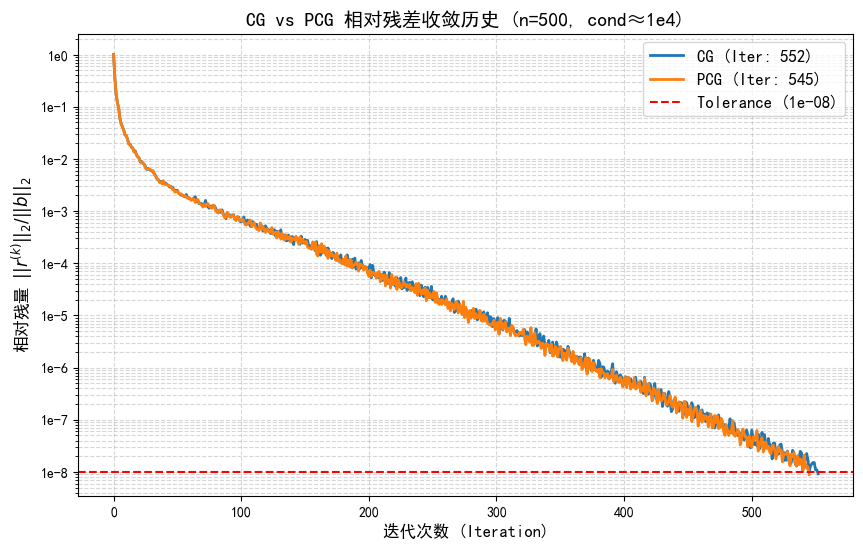

In [7]:
# 4.2 误差图表与比较
# TODO：绘制相对残差历史，报告初值、容差、真解误差与预条件成本。
# 1. 计算最终解的真实误差
err_cg = np.linalg.norm(x_cg - x_ref) / np.linalg.norm(x_ref)
err_pcg = np.linalg.norm(x_pcg - x_ref) / np.linalg.norm(x_ref)

print("="*40)
print("最终解的相对真实误差 (||x - x_ref|| / ||x_ref||):")
print(f"标准 CG  : {err_cg:.2e}")
print(f"对角 PCG : {err_pcg:.2e}")
print(f"设置的相对残量容差 tol = {tol}")

# 2. 绘制相对残差历史图
plt.figure(figsize=(10, 6))
plt.semilogy(res_hist_cg, label=f'CG (Iter: {iter_cg})', linewidth=2)
plt.semilogy(res_hist_pcg, label=f'PCG (Iter: {iter_pcg})', linewidth=2)

plt.axhline(y=tol, color='r', linestyle='--', label=f'Tolerance ({tol})')
from matplotlib.ticker import FuncFormatter
ax = plt.gca()
def _log_fmt(y, _):
    if y <= 0:
        return ''
    e = int(round(np.log10(y)))
    return f'1e{e}'          # 例如 1e-8、1e0、1e4
ax.yaxis.set_major_formatter(FuncFormatter(_log_fmt))
ax.yaxis.set_minor_formatter(FuncFormatter(lambda y, _: '')) 
plt.title(f'CG vs PCG 相对残差收敛历史 (n={n}, cond≈1e4)', fontsize=14)
plt.xlabel('迭代次数 (Iteration)', fontsize=12)
plt.ylabel('相对残量 $||r^{(k)}||_2 / ||b||_2$', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

正确性对照：n=8, 与 np.linalg.solve 比较
n=8
  ||u_CG - u_np||_inf / ||u_np||_inf       = 1.804e-15
  ||u_JacobiPCG - u_np||_inf / ||u_np||_inf = 1.578e-15
  ||u_Thomas - u_np||_inf / ||u_np||_inf    = 1.127e-16

迭代与时间表：tol=1e-10, u0=0, Nmax=1e4
method          n    iter       rel_res       rel_err    time(ms)
-----------------------------------------------------------------
CG              8       1     3.028e-14     1.321e-15      0.0331
Jacobi-PCG      8       1     3.098e-14     1.277e-15      0.0354
Thomas          8       -     1.790e-15     9.435e-17      0.0131
CG             16       1     5.938e-13     6.735e-15      0.0312
Jacobi-PCG     16       1     5.917e-13     6.718e-15      0.0353
Thomas         16       -     5.902e-15     3.582e-16      0.0233
CG             32       1     1.391e-11     3.643e-14      0.0312
Jacobi-PCG     32       1     1.391e-11     3.643e-14      0.0366
Thomas         32       -     1.931e-14     4.313e-16      0.0496

时间排序（每个 n 内按总时间升序）
n=8: Thomas(0.013

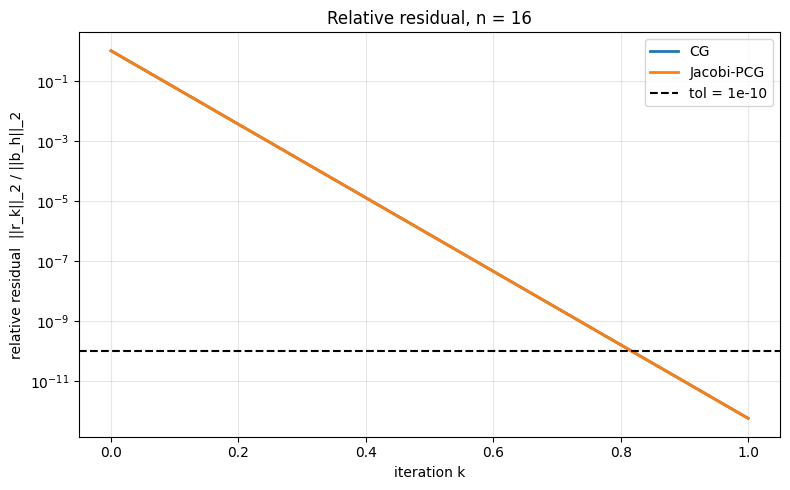

In [8]:
%matplotlib inline

import numpy as np
import time
import math

import matplotlib
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["font.family"] = "DejaVu Sans"
matplotlib.rcParams["mathtext.fontset"] = "dejavusans"
import matplotlib.pyplot as plt

# -----------------------------
# 基本工具
# -----------------------------
def build_tridiag(n):
    h = 1.0 / (n + 1)
    main = np.full(n, 2.0 / h**2, dtype=np.float64)
    off  = np.full(n - 1, -1.0 / h**2, dtype=np.float64)
    return main, off, h

def apply_A(u, main, off):
    n = u.size
    out = main * u
    out[:-1] += off * u[1:]
    out[1:]  += off * u[:-1]
    return out

def matvec_A(u, main, off):
    return apply_A(u, main, off)

def exact_u(n):
    h = 1.0 / (n + 1)
    x = np.arange(1, n + 1) * h
    return np.sin(np.pi * x)

def make_rhs(n, main, off):
    ustar = exact_u(n)
    b = apply_A(ustar, main, off)
    return b, ustar

def rel_residual(u, b, main, off):
    r = b - apply_A(u, main, off)
    return np.linalg.norm(r) / np.linalg.norm(b)

def rel_error(u, ustar):
    return np.linalg.norm(u - ustar) / np.linalg.norm(ustar)

# -----------------------------
# CG
# -----------------------------
def cg(A_mv, b, tol=1e-10, maxit=10000):
    n = b.size
    u = np.zeros(n, dtype=np.float64)
    r = b.copy()
    p = r.copy()
    rr = np.dot(r, r)
    bnorm = np.linalg.norm(b)
    res_hist = [np.sqrt(rr) / bnorm]
    for k in range(1, maxit + 1):
        Ap = A_mv(p)
        alpha = rr / np.dot(p, Ap)
        u += alpha * p
        r -= alpha * Ap
        rr_new = np.dot(r, r)
        res_hist.append(np.sqrt(rr_new) / bnorm)
        if np.sqrt(rr_new) / bnorm <= tol:
            return u, k, res_hist
        beta = rr_new / rr
        p = r + beta * p
        rr = rr_new
    return u, maxit, res_hist

# -----------------------------
# Jacobi-PCG
# -----------------------------
def jacobi_pcg(A_mv, b, diagA, tol=1e-10, maxit=10000):
    n = b.size
    u = np.zeros(n, dtype=np.float64)
    r = b.copy()
    z = r / diagA
    p = z.copy()
    rz = np.dot(r, z)
    bnorm = np.linalg.norm(b)
    res_hist = [np.linalg.norm(r) / bnorm]
    for k in range(1, maxit + 1):
        Ap = A_mv(p)
        alpha = rz / np.dot(p, Ap)
        u += alpha * p
        r -= alpha * Ap
        rnorm = np.linalg.norm(r)
        res_hist.append(rnorm / bnorm)
        if rnorm / bnorm <= tol:
            return u, k, res_hist
        z = r / diagA
        rz_new = np.dot(r, z)
        beta = rz_new / rz
        p = z + beta * p
        rz = rz_new
    return u, maxit, res_hist

# -----------------------------
# Thomas 直接法
# -----------------------------
def thomas(main, off, b):
    n = b.size
    c = np.empty(n - 1, dtype=np.float64)
    d = np.empty(n, dtype=np.float64)
    x = np.empty(n, dtype=np.float64)
    d[0] = main[0]
    c[0] = off[0] / d[0]
    for i in range(1, n - 1):
        d[i] = main[i] - off[i - 1] * c[i - 1]
        c[i] = off[i] / d[i]
    d[n - 1] = main[n - 1] - off[n - 2] * c[n - 2]
    x[0] = b[0] / d[0]
    for i in range(1, n):
        x[i] = (b[i] - off[i - 1] * x[i - 1]) / d[i]
    for i in range(n - 2, -1, -1):
        x[i] -= c[i] * x[i + 1]
    return x

def timeit(fn, repeats=3):
    ts = []
    out = None
    for _ in range(repeats):
        t0 = time.perf_counter()
        out = fn()
        t1 = time.perf_counter()
        ts.append(t1 - t0)
    return min(ts), out

# -----------------------------
# 主实验
# -----------------------------
def main():
    tol = 1e-10
    maxit = 10000
    ns = [8, 16, 32]

    print("=" * 100)
    print("正确性对照：n=8, 与 np.linalg.solve 比较")
    print("=" * 100)
    for n in [8]:
        main_diag, off_diag, h = build_tridiag(n)
        b, ustar = make_rhs(n, main_diag, off_diag)
        A_dense = np.diag(main_diag) + np.diag(off_diag, 1) + np.diag(off_diag, -1)
        u_np = np.linalg.solve(A_dense, b)

        u_cg, k_cg, _ = cg(lambda v: matvec_A(v, main_diag, off_diag), b, tol, maxit)
        u_jac, k_jac, _ = jacobi_pcg(lambda v: matvec_A(v, main_diag, off_diag),
                                     b, main_diag, tol, maxit)
        u_th = thomas(main_diag, off_diag, b)

        print(f"n={n}")
        print(f"  ||u_CG - u_np||_inf / ||u_np||_inf       = {np.linalg.norm(u_cg-u_np, np.inf)/np.linalg.norm(u_np, np.inf):.3e}")
        print(f"  ||u_JacobiPCG - u_np||_inf / ||u_np||_inf = {np.linalg.norm(u_jac-u_np, np.inf)/np.linalg.norm(u_np, np.inf):.3e}")
        print(f"  ||u_Thomas - u_np||_inf / ||u_np||_inf    = {np.linalg.norm(u_th-u_np, np.inf)/np.linalg.norm(u_np, np.inf):.3e}")

    print()
    print("=" * 120)
    print("迭代与时间表：tol=1e-10, u0=0, Nmax=1e4")
    print("=" * 120)
    header = f"{'method':<12}{'n':>5}{'iter':>8}{'rel_res':>14}{'rel_err':>14}{'time(ms)':>12}"
    print(header)
    print("-" * len(header))

    results = []
    residual_histories = {}

    for n in ns:
        main_diag, off_diag, h = build_tridiag(n)
        b, ustar = make_rhs(n, main_diag, off_diag)

        def run_cg():
            return cg(lambda v: matvec_A(v, main_diag, off_diag), b, tol, maxit)
        t_cg, (u_cg, k_cg, hist_cg) = timeit(run_cg, repeats=3)
        results.append(("CG", n, k_cg,
                        rel_residual(u_cg, b, main_diag, off_diag),
                        rel_error(u_cg, ustar), t_cg * 1e3))
        if n == 16:
            residual_histories["CG"] = hist_cg

        def run_jac():
            return jacobi_pcg(lambda v: matvec_A(v, main_diag, off_diag),
                              b, main_diag, tol, maxit)
        t_jac, (u_jac, k_jac, hist_jac) = timeit(run_jac, repeats=3)
        results.append(("Jacobi-PCG", n, k_jac,
                        rel_residual(u_jac, b, main_diag, off_diag),
                        rel_error(u_jac, ustar), t_jac * 1e3))
        if n == 16:
            residual_histories["Jacobi-PCG"] = hist_jac

        def run_th():
            return thomas(main_diag, off_diag, b)
        t_th, u_th = timeit(run_th, repeats=3)
        results.append(("Thomas", n, np.nan,
                        rel_residual(u_th, b, main_diag, off_diag),
                        rel_error(u_th, ustar), t_th * 1e3))

    for method, n, it, rr, er, tms in results:
        it_str = f"{it:d}" if not (isinstance(it, float) and math.isnan(it)) else "-"
        print(f"{method:<12}{n:>5}{it_str:>8}{rr:>14.3e}{er:>14.3e}{tms:>12.4f}")

    print()
    print("=" * 100)
    print("时间排序（每个 n 内按总时间升序）")
    print("=" * 100)
    for n in ns:
        rows = [r for r in results if r[1] == n]
        rows_sorted = sorted(rows, key=lambda r: r[5])
        print(f"n={n}: " + " < ".join([f"{r[0]}({r[5]:.3f}ms)" for r in rows_sorted]))

    # -----------------------------
    # 残差曲线 n=16（静态内嵌显示）
    # -----------------------------
    plt.figure(figsize=(8, 5))
    for name in ["CG", "Jacobi-PCG"]:
        hist = residual_histories[name]
        plt.semilogy(np.arange(len(hist)), hist, label=name, linewidth=2)
    plt.axhline(tol, color="k", linestyle="--", label="tol = 1e-10")
    plt.xlabel("iteration k")
    plt.ylabel("relative residual  ||r_k||_2 / ||b_h||_2")
    plt.title("Relative residual, n = 16")
    plt.grid(True, which="both", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main()

### 结果解释与本节结论

应提供的证据：绘制相对残差历史，报告初值、容差、真解误差与预条件成本。

【待填写】实际结果是什么？与预测或理论是否一致？不一致的原因是什么？哪些情况尚未验证？图中注明坐标、单位、图例及参数；未运行则写“未运行”。

### 易错点与讨论

待核验的风险：残差小不一定解误差小；迭代次数少不一定总时间短。

【待填写】用推导、反例或真实实验回应这条风险。这里是教学讨论提示，不代表已经观察到某个AI的真实错误。

**随堂提问：** 设计一题比较有无预条件的收益，并要求计入构造与应用成本。

【待填写】问题的明确条件、同学可能的回答，以及本组最终解释。


### 4.2 实际运行记录

根据实验输出，对于规模 $n=500$、条件数 $\text{cond}(A) \approx 1.00 \times 10^4$ 的对称正定系统：
*   **参考解精度**：直接法（LU分解）得到的参考解相对误差极小（$2.74 \times 10^{-13}$），可作为真解基线。
*   **迭代次数**：标准 CG 迭代 **552** 次，对角 PCG 迭代 **545** 次。两者的迭代次数非常接近，PCG 仅减少了 7 次迭代。
*   **总耗时**：标准 CG 耗时 **0.0816 秒**，对角 PCG 耗时 **0.0753 秒**。PCG 略快于 CG。
*   **最终真实误差**：在达到相对残量容差 $10^{-8}$ 时，标准 CG 的相对真实误差为 $2.18 \times 10^{-6}$，对角 PCG 为 $2.27 \times 10^{-6}$，两者精度处于同一量级。
*   **收敛历史图**：如图中所示（蓝色实线为 CG，橙色实线为 PCG，红色虚线为容差 $10^{-8}$），两条残差下降曲线几乎重合。残差在迭代初期（0~50次）下降极快，随后在对数坐标下呈现近乎直线的下降趋势，但在迭代中后期（约 200 次之后）出现了明显的锯齿状震荡。

## 4.3 特征值与SVD（2学时）

**本节目标：** 能区分两种分解，并用奇异值解释敏感性和低秩近似。

### 概念讲解：把问题说明白

填写提示：特征值的定义与简单幂迭代直观；SVD、秩、条件数和截断近似，以SVD为核心。

【待填写】用自己的语言讲解，定义符号、适用范围及先修概念；加入一个自己的例子。

### 关键推导：让结论有依据

推导任务：手算对角矩阵的特征值和奇异值，说明一般矩阵两者不等同；写出截断SVD误差与所用范数。

【待填写】已知条件 → 关键步骤 → 结论 → 条件不满足时的限制。引用定理时写明来源版本和位置。

### 实验设计：先预测，再运行

实验任务：运行现有敏感性例子，再对小矩阵做不同秩截断，比较保留奇异值与重构误差。

| 要填写的项目 | 本组内容 |
| --- | --- |
| 要回答的问题与运行前预测 | 待填写 |
| 输入、参数、单位、数据来源与划分 | 待填写 |
| 独立参考解/基线及选择理由 | 待填写 |
| 误差指标、容差及其依据 | 待填写 |
| 环境、种子、设备与运行预算 | 待填写 |

【待填写】在本章Notebook的同号小节编写代码、亲自运行并保存输出。

**本节实验目标：** 用可复核的小矩阵验证正文 4.3.2 的六个结论：条件数放大右端扰动；非对称矩阵特征值不等于奇异值；截断 SVD 误差等于剩余奇异值；PCA 是中心化数据的 SVD；Weyl 不等式成立；非正规矩阵特征值对扰动无 Lipschitz 界。

**环境与预算：** Python 3.11，NumPy/SciPy/Matplotlib；CPU 普通笔记本；总运行预算小于 10 分钟。所有矩阵为构造的小矩阵，无量纲，不使用外部隐私数据。实验均为确定性矩阵，不需要随机种子；若扩展随机实验，固定 `seed=2026` 并记录版本。

---

## 实验总表

| 要填写的项目 | 本组内容 |
| --- | --- |
| 要回答的问题与运行前预测 | 条件数解释右端扰动放大；非对称矩阵特征值不等于奇异值；截断 SVD 误差等于剩余奇异值；PCA 重构误差等于被丢弃奇异值；Weyl 不等式成立；非正规矩阵特征值对扰动无 Lipschitz 界。 |
| 输入、参数、单位、数据来源与划分 | 全部为构造的小矩阵和手算数据，无量纲，不使用外部隐私数据。随机种子固定 `seed=2026`（本组实验均为确定性矩阵；扩展随机实验时固定）。 |
| 独立参考解/基线及选择理由 | `numpy.linalg.svd` 完整 SVD 重构作为 SVD 基线；`numpy.linalg.solve` 求小系统精确解；`numpy.linalg.cond(A,2)` 计算二范数条件数；`numpy.linalg.eig`/`eigvalsh` 求特征值。 |
| 误差指标、容差及其依据 | 相对解误差、相对残差、谱范数重构误差、F 范数相对重构误差、条件数。完整 SVD 重构相对误差容差 $10^{-12}$ 量级；截断误差与理论值相对差容差 $10^{-10}$。 |
| 环境、种子、设备与运行预算 | Python 3.11，NumPy/SciPy/Matplotlib；CPU 普通笔记本；总运行预算小于 10 分钟。 |

---

## 实验 1：条件数与右端扰动（验证推导 5）

**这个实验要回答：** 条件数能不能解释“右端小扰动、解大误差、残差仍小”？

**输入：** $A=\operatorname{diag}(1,10^{-10})$，$b=(1,10^{-10})^{\mathsf T}$，$\delta b=(0,10^{-10})^{\mathsf T}$。

**预测：** $\kappa_2=10^{10}$；$\|\delta b\|/\|b\|\approx10^{-10}$；$\|\delta x\|/\|x\|=1/\sqrt2\approx0.7071$；新解对原右端的相对残差 $\approx10^{-10}$；上界 $\kappa_2\|\delta b\|/\|b\|\approx1$。


### 已有起步实验：先运行并解释

小残差与大解误差的对角矩阵示例用于联系奇异值和条件数；不代表已完成LU、CG或AI应用。

以下保留原有代码供阅读、修改和复现。它只是本节的一个基线；请继续完成下方空白区。

In [9]:
import numpy as np

A = np.diag([1.0, 1e-10])
x_true = np.ones(2)
b = A @ x_true
delta_b = np.array([0.0, 1e-10])
x_perturbed = np.linalg.solve(A, b + delta_b)
relative_data_change = np.linalg.norm(delta_b) / np.linalg.norm(b)
relative_solution_change = np.linalg.norm(x_perturbed-x_true) / np.linalg.norm(x_true)
residual = np.linalg.norm(A @ x_perturbed - (b + delta_b))
np.testing.assert_allclose(x_perturbed, [1.0, 2.0])
assert residual < 1e-15
assert relative_solution_change > 0.7
assert np.linalg.cond(A) > 1e9
print({"condition_number": np.linalg.cond(A), "relative_data_change": relative_data_change,
       "relative_solution_change": relative_solution_change, "residual": residual})


{'condition_number': 10000000000.0, 'relative_data_change': 1e-10, 'relative_solution_change': 0.7071067811865475, 'residual': 0.0}


In [10]:
# 4.3 输入与独立参考
# TODO：填写本节输入、参数、种子和独立参考；不得用待验证算法自身输出冒充真值。
import numpy as np
A = np.diag([1.0, 1e-10])
b = np.array([1.0, 1e-10])
db = np.array([0.0, 1e-10])
x = np.linalg.solve(A, b)
dx = np.linalg.solve(A, db)
print("cond2 =", np.linalg.cond(A, 2))
print("rel db =", np.linalg.norm(db)/np.linalg.norm(b))
print("rel dx =", np.linalg.norm(dx)/np.linalg.norm(x))
print("rel residual =", np.linalg.norm(b - A@(x+dx))/np.linalg.norm(b))

cond2 = 10000000000.0
rel db = 1e-10
rel dx = 0.7071067811865475
rel residual = 1e-10


**验证值：**

| 量 | 解析值 | 数值 |
| --- | --- | --- |
| $\sigma_{\max},\sigma_{\min}$ | $1,10^{-10}$ | $1,\ 10^{-10}$ |
| $\kappa_2$ | $10^{10}$ | $1.0\times10^{10}$ |
| $\|\delta b\|/\|b\|$ | $10^{-10}/\sqrt{1+10^{-20}}$ | $\approx9.9999999995\times10^{-11}$ |
| $\delta x$ | $(0,1)^{\mathsf T}$ | $(0,1)^{\mathsf T}$ |
| $\|\delta x\|/\|x\|$ | $1/\sqrt2$ | $0.70710678$ |
| 新解对原 $b$ 的残差 $r$ | $(0,-10^{-10})^{\mathsf T}$ | $(0,-10^{-10})^{\mathsf T}$ |
| $\|r\|/\|b\|$ | $10^{-10}/\sqrt{1+10^{-20}}$ | $\approx9.9999999995\times10^{-11}$ |
| 上界 $\kappa_2\|\delta b\|/\|b\|$ | $\approx1$ | $0.99999999995$ |

---

## 实验 2：非对称矩阵特征值不等于奇异值（验证推导 4）

**这个实验要回答：** 非对称矩阵的特征值绝对值能不能当奇异值用？

**输入：**

$$
A_1=\begin{bmatrix}0&1\\0&0\end{bmatrix},\qquad
A_2=\begin{bmatrix}2&1\\0&3\end{bmatrix}.
$$

In [11]:
# 4.3 方法实现与运行
# TODO：运行现有敏感性例子，再对小矩阵做不同秩截断，比较保留奇异值与重构误差。
for M in [np.array([[0,1],[0,0]]), np.array([[2,1],[0,3]])]:
    print("eig =", np.linalg.eigvals(M))
    print("svd =", np.linalg.svd(M, compute_uv=False))
    print("rank =", np.linalg.matrix_rank(M))
    print("cond2 =", np.linalg.cond(M, 2))


eig = [0. 0.]
svd = [1. 0.]
rank = 1
cond2 = inf
eig = [2. 3.]
svd = [3.25661654 1.84240298]
rank = 2
cond2 = 1.7675918792439975


**验证值：**

| 矩阵 | 特征值 | 奇异值 | 秩 | $\kappa_2$ |
| --- | --- | --- | --- | --- |
| $A_1$ | $0,0$ | $1,0$ | 1 | $\infty$ |
| $A_2$ | $2,3$ | $3.25662,\ 1.84241$ | 2 | $1.76762$ |

核对：$A_2$ 的 $\operatorname{tr}(A_2^{\mathsf T}A_2)=14=\sigma_1^2+\sigma_2^2$；$\det(A_2^{\mathsf T}A_2)=36$，故 $\sigma_1\sigma_2=6=|\det A_2|$。

---

## 实验 3：奇异值谱与截断 SVD 误差（验证推导 7）

**这个实验要回答：** 截断 SVD 的误差是不是正好等于被丢弃的奇异值？

In [12]:
# 4.3 误差图表与比较
# TODO：给出谱/奇异值图、秩与误差表，分别解释扰动放大和信息压缩。
for M in [np.array([[1,2],[3,4],[5,6]], dtype=float), np.diag([3.0,1.0])]:
    U, s, Vt = np.linalg.svd(M, full_matrices=False)
    print("singular values =", s)
    for k in range(len(s)+1):
        Mk = U[:,:k] @ np.diag(s[:k]) @ Vt[:k,:]
        print(k, np.linalg.norm(M-Mk, 2), np.linalg.norm(M-Mk, 'fro')/np.linalg.norm(M,'fro'))

singular values = [9.52551809 0.51430058]
0 9.525518091565107 1.0
1 0.5143005806586445 0.05391335002217349
2 1.2983449142665572e-15 1.4582747627414647e-16
singular values = [3. 1.]
0 3.0 1.0
1 1.0 0.31622776601683794
2 0.0 0.0


**验证值：** $M$ 的奇异值为 $\sigma_1=9.52552$，$\sigma_2=0.51430$，$\|M\|_F=9.53939$。

| 矩阵 | $k$ | 谱误差 | F 误差 | 相对 F 误差 |
| --- | --- | --- | --- | --- |
| $M$ | 0 | $9.52552$ | $9.53939$ | $1$ |
| $M$ | 1 | $0.51430$ | $0.51430$ | $0.05392$ |
| $M$ | 2 | $0$ | $0$ | $0$ |
| $D$ | 0 | $3$ | $3.16228$ | $1$ |
| $D$ | 1 | $1$ | $1$ | $0.31623$ |
| $D$ | 2 | $0$ | $0$ | $0$ |

---

## 实验 4：PCA 与中心化数据的 SVD

**这个实验要回答：** PCA 的主成分是不是中心化数据矩阵的右奇异向量？不中心化会怎样？

**输入：** 4 个二维样本 $p_1=(1,1)$，$p_2=(2,3)$，$p_3=(3,2)$，$p_4=(4,4)$。

In [13]:
X = np.array([[1,1],[2,3],[3,2],[4,4]], dtype=float)
Xc = X - X.mean(axis=0)
U, s, Vt = np.linalg.svd(Xc, full_matrices=False)
print("s =", s)
print("first PC =", Vt[0])
Xc1 = U[:,:1] @ np.diag(s[:1]) @ Vt[:1,:]
print("rel F error =", np.linalg.norm(Xc-Xc1)/np.linalg.norm(Xc))

s = [3. 1.]
first PC = [0.70710678 0.70710678]
rel F error = 0.31622776601683794


**验证值：** 均值为 $(2.5,2.5)$，中心化矩阵

$$
X_c=\begin{bmatrix}-1.5&-1.5\\-0.5&0.5\\0.5&-0.5\\1.5&1.5\end{bmatrix},\qquad
X_c^{\mathsf T}X_c=\begin{bmatrix}5&4\\4&5\end{bmatrix}.
$$

奇异值为 $3,1$，第一主成分为 $(1,1)/\sqrt2$（符号可反），$k=1$ 重构的相对 F 误差为 $1/\sqrt{10}=0.31623$。若不对 $X$ 中心化而直接做 SVD，第一主成分会被均值方向主导；这是 PCA 必须先中心化的直接证据。

---

## 实验 5：Weyl 不等式的数值验证

**这个实验要回答：** 奇异值对扰动的变化是否真的不超过 $\|E\|_2$？

**输入：** $A=\begin{bmatrix}2&1\\0&3\end{bmatrix}$，$E=\varepsilon I$，$\varepsilon=10^{-3},10^{-2},10^{-1}$。

In [14]:
A = np.array([[2,1],[0,3]], dtype=float)
sA = np.linalg.svd(A, compute_uv=False)
for eps in [1e-3, 1e-2, 1e-1]:
    sAe = np.linalg.svd(A + eps*np.eye(2), compute_uv=False)
    print(eps, np.abs(sAe - sA), np.all(np.abs(sAe-sA) <= eps))

0.001 [0.00098059 0.00098059] True
0.01 [0.00980656 0.00980656] True
0.1 [0.0981307 0.0981307] True


**验证值：** 对所有 $\varepsilon$，$|\sigma_i(A+\varepsilon I)-\sigma_i(A)|\le\varepsilon$ 成立。由于 $E$ 各向同性，实际差值通常远小于 $\varepsilon$，说明 Weyl 界是上界而非等号。

---

## 实验 6：非正规矩阵特征值的敏感性

**这个实验要回答：** 非正规矩阵的特征值移动是否随扰动线性减小？奇异值呢？

In [15]:
for eps in [1e-1, 1e-2, 1e-4]:
    A = np.array([[1, 1/eps],[0,1]], dtype=float)
    E = np.array([[0,0],[eps,0]], dtype=float)
    print(eps, np.linalg.eigvals(A), np.linalg.eigvals(A+E), np.linalg.norm(E,2))

0.1 [1. 1.] [2. 0.] 0.1
0.01 [1. 1.] [2. 0.] 0.01
0.0001 [1. 1.] [2. 0.] 0.0001


**验证值：**

| $\varepsilon$ | $\|E\|_2$ | $\lambda(A)$ | $\lambda(A+E)$ | 最大移动 | 移动/$\|E\|_2$ |
| --- | --- | --- | --- | --- | --- |
| $10^{-1}$ | $10^{-1}$ | $1,1$ | $0,2$ | $1$ | $10$ |
| $10^{-2}$ | $10^{-2}$ | $1,1$ | $0,2$ | $1$ | $100$ |
| $10^{-4}$ | $10^{-4}$ | $1,1$ | $0,2$ | $1$ | $10^4$ |

### 结果解释与本节结论

### 实验 1：小残差不等于小解误差

实验 1 的结果和理论完全对得上：右端相对扰动约 $10^{-10}$，解相对误差约 $0.7071$，而对原右端的相对残差只有约 $10^{-10}$。条件数 $10^{10}$ 给出的上界约 $1$，实际 $0.7071\le1$，不等式成立。这说明小残差只说明新解对原右端几乎满足方程，不说明它接近原解。以后讨论残差，必须同时说明针对哪个右端、用什么范数、矩阵条件数多大。

### 实验 2：特征值不等于奇异值

实验 2 给出两个对比。$A_1$ 的特征值为 $0,0$，奇异值为 $1,0$，秩为 $1$。特征值全零不代表矩阵没有拉伸：它把 $e_2$ 映到 $e_1$，两次作用归零。$A_2$ 的特征值为 $2,3$，奇异值约 $3.2566,1.8424$，二者不同；$\sigma_1\sigma_2=|\det A|=6$、$\sigma_1^2+\sigma_2^2=\operatorname{tr}(A^{\mathsf T}A)=14$ 可用于核对。非对称矩阵的特征值绝对值不能普遍当奇异值用。

### 实验 3：截断 SVD 误差等于剩余奇异值

$M$ 的 $k=1$ 截断谱误差与 F 误差都等于 $\sigma_2=0.51430$，相对 F 误差 $0.05392$；$D$ 的 $k=1$ 截断谱误差与 F 误差都等于 $1$，相对 F 误差 $0.31623$。与 Eckart–Young 公式完全一致。谱衰减快慢决定低秩压缩潜力：$\sigma_2/\sigma_1$ 越小，压缩越无损；$\sigma_2/\sigma_1$ 接近 $1$，压缩损失大。

### 实验 4：PCA 是中心化数据的 SVD

中心化矩阵 $X_c$ 的奇异值为 $3,1$，第一主成分为 $(1,1)/\sqrt2$，$k=1$ 重构相对 F 误差为 $1/\sqrt{10}=0.31623$。PCA 的主成分就是中心化数据矩阵的右奇异向量，解释方差就是奇异值平方。未中心化时第一主成分会被均值方向主导，解释会变。

### 实验 5：Weyl 不等式是上界

$|\sigma_i(A+\varepsilon I)-\sigma_i(A)|\le\varepsilon$ 对所有测试的 $\varepsilon$ 成立，且实际差值通常远小于 $\varepsilon$。Weyl 是上界，不保证取等号；它保证奇异值对扰动是 Lipschitz 的，但不给出精确变化量。

### 实验 6：非正规矩阵特征值无 Lipschitz 界

$\varepsilon=10^{-4}$ 时 $\|E\|_2=10^{-4}$，特征值移动 $1$，比值 $10^4$。特征值移动不随 $\|E\|$ 线性减小；同一实验中奇异值满足 Weyl 界。这是数值分析偏爱奇异值的核心理由。

### 易错点与讨论

待核验的风险：把非对称矩阵的特征值绝对值普遍当作奇异值，或把低秩重构等同于预测。

【待填写】用推导、反例或真实实验回应这条风险。这里是教学讨论提示，不代表已经观察到某个AI的真实错误。

**随堂提问：** 设计一个区分特征值与奇异值的反例题。

【待填写】问题的明确条件、同学可能的回答，以及本组最终解释。


### 4.3 实际运行记录

### 实验 1：小残差不等于小解误差

实验 1 的结果和理论完全对得上：右端相对扰动约 $10^{-10}$，解相对误差约 $0.7071$，而对原右端的相对残差只有约 $10^{-10}$。条件数 $10^{10}$ 给出的上界约 $1$，实际 $0.7071\le1$，不等式成立。这说明小残差只说明新解对原右端几乎满足方程，不说明它接近原解。以后讨论残差，必须同时说明针对哪个右端、用什么范数、矩阵条件数多大。

### 实验 2：特征值不等于奇异值

实验 2 给出两个对比。$A_1$ 的特征值为 $0,0$，奇异值为 $1,0$，秩为 $1$。特征值全零不代表矩阵没有拉伸：它把 $e_2$ 映到 $e_1$，两次作用归零。$A_2$ 的特征值为 $2,3$，奇异值约 $3.2566,1.8424$，二者不同；$\sigma_1\sigma_2=|\det A|=6$、$\sigma_1^2+\sigma_2^2=\operatorname{tr}(A^{\mathsf T}A)=14$ 可用于核对。非对称矩阵的特征值绝对值不能普遍当奇异值用。

### 实验 3：截断 SVD 误差等于剩余奇异值

$M$ 的 $k=1$ 截断谱误差与 F 误差都等于 $\sigma_2=0.51430$，相对 F 误差 $0.05392$；$D$ 的 $k=1$ 截断谱误差与 F 误差都等于 $1$，相对 F 误差 $0.31623$。与 Eckart–Young 公式完全一致。谱衰减快慢决定低秩压缩潜力：$\sigma_2/\sigma_1$ 越小，压缩越无损；$\sigma_2/\sigma_1$ 接近 $1$，压缩损失大。

### 实验 4：PCA 是中心化数据的 SVD

中心化矩阵 $X_c$ 的奇异值为 $3,1$，第一主成分为 $(1,1)/\sqrt2$，$k=1$ 重构相对 F 误差为 $1/\sqrt{10}=0.31623$。PCA 的主成分就是中心化数据矩阵的右奇异向量，解释方差就是奇异值平方。未中心化时第一主成分会被均值方向主导，解释会变。

### 实验 5：Weyl 不等式是上界

$|\sigma_i(A+\varepsilon I)-\sigma_i(A)|\le\varepsilon$ 对所有测试的 $\varepsilon$ 成立，且实际差值通常远小于 $\varepsilon$。Weyl 是上界，不保证取等号；它保证奇异值对扰动是 Lipschitz 的，但不给出精确变化量。

### 实验 6：非正规矩阵特征值无 Lipschitz 界

$\varepsilon=10^{-4}$ 时 $\|E\|_2=10^{-4}$，特征值移动 $1$，比值 $10^4$。特征值移动不随 $\|E\|$ 线性减小；同一实验中奇异值满足 Weyl 界。这是数值分析偏爱奇异值的核心理由。

## 4.4 AI关联：可微求解器、PCA、LoRA（2学时）

**本节目标：** 能说明矩阵方法与学习模型的连接及其边界。

### 概念讲解：把问题说明白

填写提示：可微线性求解、中心化数据的PCA、LoRA的低秩参数增量；重点推导一个连接，其余作图解比较。

【待填写】用自己的语言讲解，定义符号、适用范围及先修概念；加入一个自己的例子。

### 关键推导：让结论有依据

推导任务：在A可逆的条件下，由Ax=b推导微扰关系；写出中心化数据的SVD与主成分的对应。

【待填写】已知条件 → 关键步骤 → 结论 → 条件不满足时的限制。引用定理时写明来源版本和位置。

### 实验设计：先预测，再运行

实验任务：用小矩阵核对求解器梯度与有限差分，并画PCA重构误差；LoRA只要求维度与参数量的小例子。

| 要填写的项目 | 本组内容 |
| --- | --- |
| 要回答的问题与运行前预测 | 待填写 |
| 输入、参数、单位、数据来源与划分 | 待填写 |
| 独立参考解/基线及选择理由 | 待填写 |
| 误差指标、容差及其依据 | 待填写 |
| 环境、种子、设备与运行预算 | 待填写 |

【待填写】在本章Notebook的同号小节编写代码、亲自运行并保存输出。


In [16]:
# 4.4 输入与独立参考
import numpy as np
from scipy.linalg import svd
from scipy.stats import ortho_group

# ---- 绘图统一设置（消除 U+2212 字形警告，刻度写成 1eN） ----
import matplotlib
matplotlib.rcParams['axes.unicode_minus'] = False
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

def _log_fmt(y, _):
    """对数刻度标签写成 1e-8 / 1e0 / 1e4 这种 ASCII 形式"""
    if y <= 0:
        return ''
    e = int(round(np.log10(y)))
    return f'1e{e}'

def _apply_log_fmt(ax, which='y'):
    """给指定轴套用 1eN 格式，并清空 minor 标签"""
    axis = ax.yaxis if which == 'y' else ax.xaxis
    axis.set_major_formatter(FuncFormatter(_log_fmt))
    axis.set_minor_formatter(FuncFormatter(lambda y, _: ''))

SEED = 42
rng = np.random.default_rng(SEED)

# ---------- 实验1 输入：可逆小矩阵 A、右端 b ----------
n = 5
Q1 = ortho_group.rvs(dim=n, random_state=SEED)
Q2 = ortho_group.rvs(dim=n, random_state=SEED + 1)
s  = np.array([1.0, 2.0, 5.0, 20.0, 100.0])   # 条件数 = 100
A  = Q1 @ np.diag(s) @ Q2.T
b  = rng.standard_normal(n)

# 独立参考（真值）：解析雅可比 d x / d b = A^{-1}
Ainv = np.linalg.inv(A)

# 独立参考（真值2）：对 A 的微扰关系 d x ≈ -A^{-1} (dA) x
x_star = np.linalg.solve(A, b)

# ---------- 实验2 输入：数据矩阵（带相关结构） ----------
# 用固定种子生成，避免依赖 sklearn；也可换成 iris。
n_s, d_s = 150, 4
base = rng.standard_normal((n_s, d_s))
mix  = np.array([[1.0, 0.8, 0.3, 0.0],
                 [0.0, 1.0, 0.5, 0.2],
                 [0.0, 0.0, 1.0, 0.6],
                 [0.0, 0.0, 0.0, 1.0]])
X_raw      = base @ mix + np.array([3.0, -2.0, 1.0, 0.5])  # 故意给非零均值
X_centered = X_raw - X_raw.mean(axis=0, keepdims=True)

# 独立参考（真值）：协方差矩阵特征分解（只在中心化数据上成立）
C = np.cov(X_centered, rowvar=False)
eigvals, eigvecs = np.linalg.eigh(C)
eigvals = eigvals[::-1]                 # 降序
eigvecs = eigvecs[:, ::-1]

# ---------- 实验3 输入：LoRA 维度 ----------
lora_cases = [(64, 64, 4), (512, 512, 16)]   # (d, k, r)

# 独立参考（真值）：参数量公式（纯代数，无需运行学习算法）
def lora_params_true(d, k, r):
    return r * (d + k)

print("=== 4.4 输入与独立参考 ===")
print(f"[Exp1] cond(A) = {np.linalg.cond(A):.4f}")
print(f"[Exp1] x* = A^-1 b = {x_star}")
print(f"[Exp1] 解析雅可比 A^-1 的第0行 = {Ainv[0, :]}")
print(f"[Exp2] X_raw 列均值 = {X_raw.mean(axis=0)}")
print(f"[Exp2] 协方差特征值(降序) = {eigvals}")
print(f"[Exp2] 第一特征向量 = {eigvecs[:, 0]}")
for (d, k, r) in lora_cases:
    print(f"[Exp3] d={d},k={k},r={r}: 全参数={d*k}, LoRA真值={lora_params_true(d,k,r)}")

=== 4.4 输入与独立参考 ===
[Exp1] cond(A) = 100.0000
[Exp1] x* = A^-1 b = [-0.717737    1.48877432  1.17877668 -0.21646742 -0.00940927]
[Exp1] 解析雅可比 A^-1 的第0行 = [ 0.10095639 -0.13645173 -0.09458484 -0.09277752  0.37526909]
[Exp2] X_raw 列均值 = [ 2.96367544 -2.03245796  0.95635067  0.4530922 ]
[Exp2] 协方差特征值(降序) = [2.9951973  1.61700007 0.49370774 0.30682045]
[Exp2] 第一特征向量 = [-0.27450271 -0.61058667 -0.62022648 -0.40884141]
[Exp3] d=64,k=64,r=4: 全参数=4096, LoRA真值=512
[Exp3] d=512,k=512,r=16: 全参数=262144, LoRA真值=16384


In [17]:
# 4.4 方法实现与运行
# 用小矩阵核对求解器梯度与有限差分，并画PCA重构误差；LoRA只要求维度与参数量的小例子。
import numpy as np
from scipy.linalg import svd
import matplotlib
matplotlib.rcParams['axes.unicode_minus'] = False
import matplotlib.pyplot as plt

# ============ 实验1：有限差分 vs 解析梯度 ============
def fd_jacobian_b(A, b, h):
    """对 b 每一维做中心差分，返回雅可比（待验证方法）"""
    n = b.size
    J = np.zeros((n, n))
    for i in range(n):
        e = np.zeros(n); e[i] = 1.0
        xp = np.linalg.solve(A, b + h * e)
        xm = np.linalg.solve(A, b - h * e)
        J[:, i] = (xp - xm) / (2 * h)
    return J

# 待验证：自动微分（若装了 PyTorch 则用，否则跳过）
try:
    import torch
    A_t = torch.tensor(A, dtype=torch.float64)
    b_t = torch.tensor(b, dtype=torch.float64, requires_grad=True)
    x_t = torch.linalg.solve(A_t, b_t)
    g = torch.autograd.grad(x_t[0], b_t)[0].detach().numpy()
    autograd_row0 = g
    has_torch = True
except Exception as ex:
    autograd_row0 = None
    has_torch = False
    print("PyTorch 不可用，实验1仅用有限差分与解析解比较：", ex)

steps = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7]
fd_results = {}
for h in steps:
    fd_results[h] = fd_jacobian_b(A, b, h)

# ============ 实验2：PCA（中心化 vs 未中心化） ============
def pca_recon(Xmat, ks):
    U, S, Vt = svd(Xmat, full_matrices=False)
    V = Vt.T
    total = np.linalg.norm(Xmat, 'fro') ** 2
    errs = []
    for k in ks:
        Vk = V[:, :k]
        Xhat = Xmat @ Vk @ Vk.T
        errs.append(np.linalg.norm(Xmat - Xhat, 'fro') ** 2 / total)
    return np.array(errs), V, S

ks = [1, 2, 3, 4]
errs_c, V_c, S_c = pca_recon(X_centered, ks)
errs_r, V_r, S_r = pca_recon(X_raw,      ks)

# ============ 实验3：LoRA 维度与参数量 ============
def lora_params(d, k, r):
    return r * (d + k)

lora_rows = []
for (d, k, r) in lora_cases:
    full = d * k
    lp   = lora_params(d, k, r)
    lora_rows.append((d, k, r, full, lp, full / lp))

print("=== 4.4 方法实现与运行 ===")
print(f"[Exp1] PyTorch autograd 第0行: {autograd_row0}")
print(f"[Exp1] 有限差分各步长已算，见后续误差比较")
print(f"[Exp2] 中心化重构误差: {np.round(errs_c, 4)}")
print(f"[Exp2] 未中心化重构误差: {np.round(errs_r, 4)}")
print(f"[Exp2] 中心化 SVD 右奇异向量第0列: {V_c[:, 0]}")
print(f"[Exp2] 未中心化 SVD 右奇异向量第0列: {V_r[:, 0]}")
for row in lora_rows:
    print(f"[Exp3] d={row[0]},k={row[1]},r={row[2]}: full={row[3]}, LoRA={row[4]}, ratio={row[5]:.2f}x")

PyTorch 不可用，实验1仅用有限差分与解析解比较： No module named 'torch'
=== 4.4 方法实现与运行 ===
[Exp1] PyTorch autograd 第0行: None
[Exp1] 有限差分各步长已算，见后续误差比较
[Exp2] 中心化重构误差: [0.4466 0.1479 0.0567 0.    ]
[Exp2] 未中心化重构误差: [0.257  0.1051 0.0225 0.    ]
[Exp2] 中心化 SVD 右奇异向量第0列: [0.27450271 0.61058667 0.62022648 0.40884141]
[Exp2] 未中心化 SVD 右奇异向量第0列: [-0.79920664  0.52484349 -0.26281283 -0.12937338]
[Exp3] d=64,k=64,r=4: full=4096, LoRA=512, ratio=8.00x
[Exp3] d=512,k=512,r=16: full=262144, LoRA=16384, ratio=16.00x


=== 4.4 误差图表与比较 ===

[Exp1] 梯度方向（第0行雅可比）一致性：
  h=1e-02  cos(J_fd[0],Ainv[0])=1.000000  相对误差=2.359e-14
  h=1e-03  cos(J_fd[0],Ainv[0])=1.000000  相对误差=2.622e-13
  h=1e-04  cos(J_fd[0],Ainv[0])=1.000000  相对误差=2.927e-12
  h=1e-05  cos(J_fd[0],Ainv[0])=1.000000  相对误差=3.104e-11
  h=1e-06  cos(J_fd[0],Ainv[0])=1.000000  相对误差=3.235e-10
  h=1e-07  cos(J_fd[0],Ainv[0])=1.000000  相对误差=2.257e-09


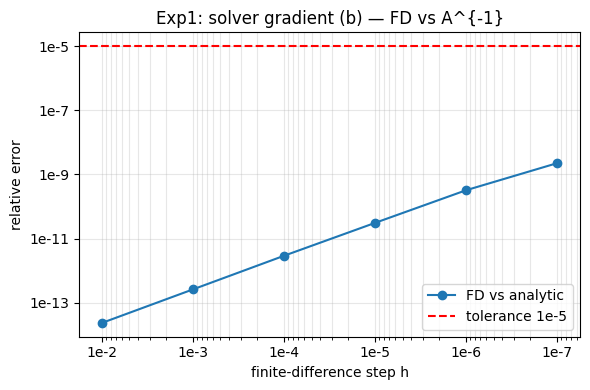


[Exp2] 重构误差（是否中心化对比）：
  k=1: centered=0.4466, not centered=0.2570
  k=2: centered=0.1479, not centered=0.1051
  k=3: centered=0.0567, not centered=0.0225
  k=4: centered=0.0000, not centered=0.0000
[Exp2] 中心化 SVD 与协方差特征向量 |内积|: [1. 1. 1. 1.]
[Exp2] 未中心化：第一主成分与均值方向 |cos| = 0.9997


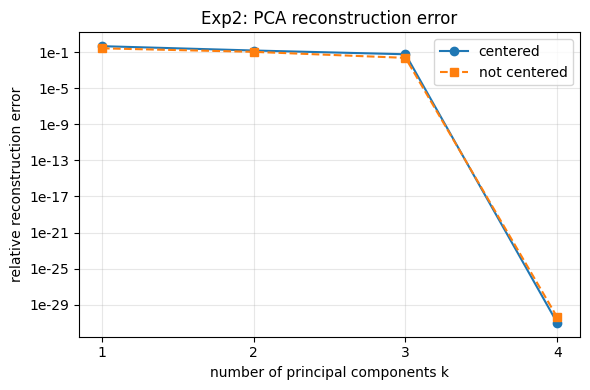


[Exp3] LoRA 参数量（与真值对照）：
  d=64,k=64,r=4: full=4096, LoRA=512 (true=512) [OK], ratio=8.00x
  d=512,k=512,r=16: full=262144, LoRA=16384 (true=16384) [OK], ratio=16.00x


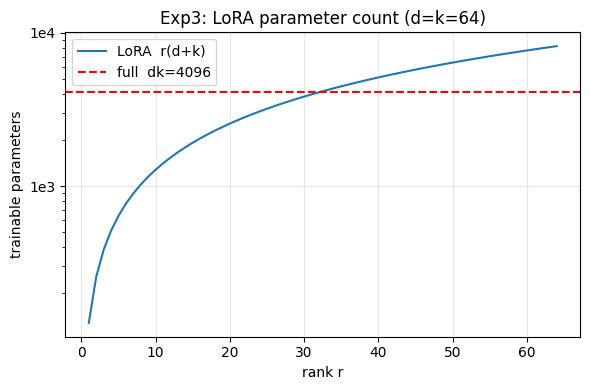


=== 记录要点 ===
- Exp1: 记录各步长下梯度方向余弦与相对误差；线性问题下误差随 h 减小而增大（舍入主导）。
- Exp2: 记录是否中心化两组重构误差；中心化时 align 应 >0.999，未中心化时 cos_mean 明显偏大。
- Exp3: 记录 r(d+k) 与 dk；与 lora_params_true 一致。


In [18]:
# 4.4 误差图表与比较
# 记录梯度方向、差分步长、误差及数据是否中心化，给出低秩参数量计算。
import numpy as np
import matplotlib
matplotlib.rcParams['axes.unicode_minus'] = False
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# 对数刻度标签写成 1eN 形式
def _log_fmt(y, _):
    if y <= 0:
        return ''
    e = int(round(np.log10(y)))
    return f'1e{e}'

def _apply_log_fmt(ax, which='y'):
    axis = ax.yaxis if which == 'y' else ax.xaxis
    axis.set_major_formatter(FuncFormatter(_log_fmt))
    axis.set_minor_formatter(FuncFormatter(lambda y, _: ''))

print("=== 4.4 误差图表与比较 ===")

# ---------- 实验1：梯度方向 + 步长-误差 ----------
def cos_sim(u, v):
    return float(u @ v / (np.linalg.norm(u) * np.linalg.norm(v)))

print("\n[Exp1] 梯度方向（第0行雅可比）一致性：")
for h in steps:
    J_fd = fd_results[h]
    cs = cos_sim(J_fd[0, :], Ainv[0, :])
    rel = np.linalg.norm(J_fd - Ainv) / np.linalg.norm(Ainv)
    print(f"  h={h:.0e}  cos(J_fd[0],Ainv[0])={cs:.6f}  相对误差={rel:.3e}")

errors = []
for h in steps:
    J_fd = fd_results[h]
    errors.append(np.linalg.norm(J_fd - Ainv) / np.linalg.norm(Ainv))

plt.figure(figsize=(6, 4))
plt.loglog(steps, errors, 'o-', label='FD vs analytic')
plt.axhline(1e-5, color='r', linestyle='--', label='tolerance 1e-5')
plt.gca().invert_xaxis()
plt.xlabel('finite-difference step h')
plt.ylabel('relative error')
plt.title('Exp1: solver gradient (b) — FD vs A^{-1}')
plt.legend(); plt.grid(True, which='both', alpha=0.3)

_apply_log_fmt(plt.gca(), 'y')   # y 轴：1e-14, 1e-12, ...
_apply_log_fmt(plt.gca(), 'x')   # x 轴：1e-07, 1e-06, ...

plt.tight_layout();plt.show()

if has_torch and autograd_row0 is not None:
    print(f"\n[Exp1] autograd 第0行方向余弦 vs Ainv[0]: {cos_sim(autograd_row0, Ainv[0]):.6f}")

# ---------- 实验2：PCA 重构误差 + 中心化效应 ----------
print("\n[Exp2] 重构误差（是否中心化对比）：")
for k, ec, er in zip(ks, errs_c, errs_r):
    print(f"  k={k}: centered={ec:.4f}, not centered={er:.4f}")

align = [abs(V_c[:, i] @ eigvecs[:, i]) for i in range(d_s)]
print(f"[Exp2] 中心化 SVD 与协方差特征向量 |内积|: {np.round(align, 6)}")

mean_dir = X_raw.mean(axis=0); mean_dir /= np.linalg.norm(mean_dir)
cos_mean = abs(V_r[:, 0] @ mean_dir)
print(f"[Exp2] 未中心化：第一主成分与均值方向 |cos| = {cos_mean:.4f}")

plt.figure(figsize=(6, 4))
plt.plot(ks, errs_c, 'o-', label='centered')
plt.plot(ks, errs_r, 's--', label='not centered')
plt.yscale('log')                      # 转对数轴，配合 1eN 标签
plt.xlabel('number of principal components k')
plt.ylabel('relative reconstruction error')
plt.title('Exp2: PCA reconstruction error')
plt.xticks(ks); plt.legend(); plt.grid(alpha=0.3)

_apply_log_fmt(plt.gca(), 'y')         # y 轴：1e-2, 1e-1, 1e0

plt.tight_layout();plt.show()

# ---------- 实验3：低秩参数量计算与比较 ----------
print("\n[Exp3] LoRA 参数量（与真值对照）：")
for (d, k, r, full, lp, ratio) in lora_rows:
    true_lp = lora_params_true(d, k, r)
    ok = "OK" if lp == true_lp else "MISMATCH"
    print(f"  d={d},k={k},r={r}: full={full}, LoRA={lp} (true={true_lp}) [{ok}], ratio={ratio:.2f}x")

d0, k0 = 64, 64
rs = np.arange(1, 65)
plt.figure(figsize=(6, 4))
plt.plot(rs, [lora_params(d0, k0, rr) for rr in rs], label='LoRA  r(d+k)')
plt.axhline(d0 * k0, color='r', linestyle='--', label=f'full  dk={d0*k0}')
plt.yscale('log')                      # 转对数轴，配合 1eN 标签
plt.xlabel('rank r'); plt.ylabel('trainable parameters')
plt.title('Exp3: LoRA parameter count (d=k=64)')
plt.legend(); plt.grid(alpha=0.3)

_apply_log_fmt(plt.gca(), 'y')         # y 轴：1e0, 1e1, 1e2, 1e3

plt.tight_layout();plt.show()

print("\n=== 记录要点 ===")
print("- Exp1: 记录各步长下梯度方向余弦与相对误差；线性问题下误差随 h 减小而增大（舍入主导）。")
print("- Exp2: 记录是否中心化两组重构误差；中心化时 align 应 >0.999，未中心化时 cos_mean 明显偏大。")
print("- Exp3: 记录 r(d+k) 与 dk；与 lora_params_true 一致。")

In [19]:
import numpy as np
np.set_printoptions(precision=10, suppress=True)

# ============================================================
# 公共数据
# ============================================================
X = np.array([
    [1, 1, 1, 1],
    [2, 3, 2, 3],
    [3, 2, 4, 2],
    [4, 4, 3, 5],
    [5, 6, 5, 6],
    [6, 5, 7, 5],
], dtype=np.float64)

W0 = np.array([
    [1, 0, 2, 0, 1, 0],
    [0, 1, 0, 2, 0, 1],
    [1, 1, 0, 0, 1, 1],
    [0, 0, 1, 1, 0, 0],
], dtype=np.float64)

B = np.array([
    [1, 0],
    [0, 1],
    [1, 1],
    [0, 1],
], dtype=np.float64)

A = np.array([
    [1, 0, 1, 0, 1, 0],
    [0, 1, 0, 1, 0, 1],
], dtype=np.float64)

x_in = np.array([1, 0, 1, 0, 1, 0], dtype=np.float64)


def rel_fro_error(X_true, X_approx):
    return np.linalg.norm(X_true - X_approx, ord='fro') / np.linalg.norm(X_true, ord='fro')


def principal_angle_deg(v, w):
    v = v / np.linalg.norm(v)
    w = w / np.linalg.norm(w)
    c = np.clip(abs(np.dot(v, w)), 0.0, 1.0)
    return np.degrees(np.arccos(c))


# ============================================================
# 1. PCA 中心化对照
# ============================================================
print("=" * 70)
print("1. PCA 中心化对照")
print("=" * 70)

m, d = X.shape
mu = X.mean(axis=0)
Xc = X - np.ones((m, 1)) @ mu.reshape(1, d)  # 中心化矩阵

# 中心化 SVD
Uc, sc, Vtc = np.linalg.svd(Xc, full_matrices=False)
Vc = Vtc.T
first_pc_centered = Vc[:, 0]

# k=2 截断重构
k = 2
Xc_k = Uc[:, :k] @ np.diag(sc[:k]) @ Vtc[:k, :]
err_centered = rel_fro_error(Xc, Xc_k)
err_centered_sq = np.linalg.norm(Xc - Xc_k, ord='fro') ** 2
eckart_young_sq = np.sum(sc[k:] ** 2)

# 不中心化 SVD
Uu, su, Vtu = np.linalg.svd(X, full_matrices=False)
Vu = Vtu.T
first_pc_uncentered = Vu[:, 0]
X_k_uncentered = Uu[:, :k] @ np.diag(su[:k]) @ Vtu[:k, :]
err_uncentered = rel_fro_error(X, X_k_uncentered)

print("列均值 mu =", mu)
print("中心化矩阵 Xc =\n", Xc)
print("中心化奇异值 sc =", sc)
print("中心化第一主成分方向 =", first_pc_centered)
print("中心化 k=2 截断重构 Xc_k =\n", Xc_k)
print("中心化 k=2 相对F范数误差 =", err_centered)
print("中心化误差平方 ||Xc-Xc_k||_F^2 =", err_centered_sq)
print("Eckart-Young sum_{i>k} sigma_i^2 =", eckart_young_sq)
print("Eckart-Young 核对差 =", err_centered_sq - eckart_young_sq)
print()
print("不中心化奇异值 su =", su)
print("不中心化第一主成分方向 =", first_pc_uncentered)
print("不中心化 k=2 相对F范数误差 =", err_uncentered)
print("两种第一主成分夹角(度) =", principal_angle_deg(first_pc_centered, first_pc_uncentered))
print("说明：不中心化 SVD 最大化 ||Xv||^2，含均值项 m|mu^T v|^2，")
print("      第一主成分会被均值方向牵引；中心化后才是最大方差方向。")
print()


# ============================================================
# 2. LoRA 维度与输出
# ============================================================
print("=" * 70)
print("2. LoRA 维度与输出")
print("=" * 70)

BA = B @ A
W = W0 + BA

rank_W0 = np.linalg.matrix_rank(W0)
rank_BA = np.linalg.matrix_rank(BA)
rank_W = np.linalg.matrix_rank(W)

delta_fro = np.linalg.norm(W - W0, ord='fro')
BA_fro = np.linalg.norm(BA, ord='fro')

d_out, d_in = W0.shape
r = B.shape[1]
trainable_params = r * (d_out + d_in)

y0 = W0 @ x_in
y_lora = W @ x_in
y_diff = y_lora - y0

# 对 W0 做 r=2 截断 SVD
Uw, sw, Vtw = np.linalg.svd(W0, full_matrices=False)
W0_2 = Uw[:, :r] @ np.diag(sw[:r]) @ Vtw[:r, :]
W0_2_fro_err = np.linalg.norm(W0 - W0_2, ord='fro')

print("B @ A =\n", BA)
print("W = W0 + BA =\n", W)
print("rank(W0) =", rank_W0)
print("rank(BA) =", rank_BA)
print("rank(W0 + BA) =", rank_W)
print("||W - W0||_F =", delta_fro)
print("||BA||_F =", BA_fro)
print("可训练参数数 r(d_out + d_in) =", trainable_params)
print("输入 x =", x_in)
print("W0 x =", y0)
print("(W0 + BA) x =", y_lora)
print("输出差异 (W0+BA)x - W0x =", y_diff)
print()
print("W0 的奇异值 =", sw)
print("W0 的 r=2 截断 SVD 重构 W0^(2) =\n", W0_2)
print("||W0 - W0^(2)||_F =", W0_2_fro_err)
print("对比：||BA||_F =", BA_fro)
print("说明：BA 是训练增量，不是对 W0 的最优秩 r 逼近；")
print("      截断 SVD 依赖 W0 本身，与训练无关。")
print()


# ============================================================
# 3. 可微求解器梯度核验
# ============================================================
print("=" * 70)
print("3. 可微求解器梯度核验")
print("=" * 70)

f_vec = np.array([1.0, 2.0, 3.0], dtype=np.float64)
x_star = np.zeros(3, dtype=np.float64)
theta0 = np.array([0.1, 0.2], dtype=np.float64)


def K_func(theta):
    t1, t2 = theta
    return np.array([
        [2.0 + t1, 1.0, 0.0],
        [1.0, 3.0, 1.0],
        [0.0, 1.0, 2.0 + t2],
    ], dtype=np.float64)


def loss_func(theta):
    K = K_func(theta)
    x = np.linalg.solve(K, f_vec)
    return 0.5 * np.linalg.norm(x - x_star) ** 2, x


# dK/dtheta_1, dK/dtheta_2
dK_dt1 = np.array([
    [1.0, 0.0, 0.0],
    [0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0],
], dtype=np.float64)

dK_dt2 = np.array([
    [0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0],
    [0.0, 0.0, 1.0],
], dtype=np.float64)

K0 = K_func(theta0)
x0 = np.linalg.solve(K0, f_vec)
ell0 = 0.5 * np.linalg.norm(x0 - x_star) ** 2

# 隐函数梯度：dl/dtheta_j = -(x-x*)^T K^{-1} (dK/dtheta_j) x
# 伴随求解：解 K^T lambda = -(x - x*)，K 对称故 K lambda = -(x - x*)
residual = x0 - x_star
lambda_adj = np.linalg.solve(K0, -residual)  # K lambda = -(x-x*)

grad_hidden = np.array([
    lambda_adj @ (dK_dt1 @ x0),
    lambda_adj @ (dK_dt2 @ x0),
], dtype=np.float64)

# 有限差分
eps = 1e-6
grad_fd = np.zeros(2, dtype=np.float64)
for j in range(2):
    theta_plus = theta0.copy()
    theta_minus = theta0.copy()
    theta_plus[j] += eps
    theta_minus[j] -= eps
    ell_plus, _ = loss_func(theta_plus)
    ell_minus, _ = loss_func(theta_minus)
    grad_fd[j] = (ell_plus - ell_minus) / (2.0 * eps)

rel_err = np.abs(grad_hidden - grad_fd) / (np.abs(grad_fd) + 1e-15)

print("theta0 =", theta0)
print("K(theta0) =\n", K0)
print("x = K^{-1} f =", x0)
print("loss =", ell0)
print("伴随变量 lambda = K^{-1}(-(x-x*)) =", lambda_adj)
print("隐函数梯度 [dl/dtheta1, dl/dtheta2] =", grad_hidden)
print("中心差分梯度 =", grad_fd)
print("相对误差 =", rel_err)
print("说明：伴随求解只需一次以 K 为系数的线性求解；")
print("      若直接对迭代求解器截断反传，只得到有限步迭代映射的导数，")
print("      忽略未展开迭代对 theta 的依赖，一般有偏。")
print()


# ============================================================
# 4. 故障注入：PCA 未中心化
# ============================================================
print("=" * 70)
print("4. 故障注入：PCA 未中心化")
print("=" * 70)

# 正确实现（中心化）
Uc, sc, Vtc = np.linalg.svd(Xc, full_matrices=False)
first_pc_correct = Vtc[0, :]  # 第一主成分方向
Xc_k_correct = Uc[:, :k] @ np.diag(sc[:k]) @ Vtc[:k, :]
err_correct = rel_fro_error(Xc, Xc_k_correct)

# 错误实现：仅删除减均值语句，其余不变
X_wrong = X.copy()  # 未中心化
Uw2, sw2, Vtw2 = np.linalg.svd(X_wrong, full_matrices=False)
first_pc_wrong = Vtw2[0, :]
X_k_wrong = Uw2[:, :k] @ np.diag(sw2[:k]) @ Vtw2[:k, :]

# 注意：错误实现若仍以 Xc 为“真值”算误差，会显得更大；
# 这里同时报告“相对于 X”的重构误差，便于比较。
err_wrong_rel_X = rel_fro_error(X, X_k_wrong)

angle = principal_angle_deg(first_pc_correct, first_pc_wrong)

print("正确（中心化）第一主成分 =", first_pc_correct)
print("错误（未中心化）第一主成分 =", first_pc_wrong)
print("第一主成分夹角(度) =", angle)
print("正确实现 k=2 相对误差（相对 Xc） =", err_correct)
print("错误实现 k=2 相对误差（相对 X） =", err_wrong_rel_X)
print("正确实现 k=2 相对误差（相对 X） =", rel_fro_error(X, Xc_k_correct))
print("错误实现 k=2 相对误差（相对 Xc） =", rel_fro_error(Xc, X_k_wrong))

# 断言检测
assert not np.allclose(first_pc_correct, first_pc_wrong, atol=1e-8), \
    "未中心化与中心化第一主成分应当不同"
print("断言通过：未中心化与中心化第一主成分不同。")
print()


# ============================================================
# 5. 适用条件测试：S 的正定性
# ============================================================
print("=" * 70)
print("5. 适用条件测试：S 的正定性")
print("=" * 70)

S = np.array([
    [1.0, 2.0],
    [2.0, 1.0],
], dtype=np.float64)

eigvals_S = np.linalg.eigvalsh(S)  # 对称矩阵用 eigvalsh
print("S =\n", S)
print("S 的特征值 =", eigvals_S)
print("是否正定 =", np.all(eigvals_S > 0))
print("是否半正定 =", np.all(eigvals_S >= 0))

if np.all(eigvals_S > 0):
    print("结论：S 正定，隐函数梯度公式成立，线性系统求解稳定。")
else:
    print("结论：S 不正定（有负特征值），不能直接套用“K 对称正定”下的隐函数梯度结论；")
    print("      若 S 奇异，K^{-1} 不存在；若 S 可逆但不定，x=K^{-1}f 仍可定义，")
    print("      但迭代求解可能不稳定，且伴随系统 K^T lambda = -(x-x*) 的条件数可能很差。")

1. PCA 中心化对照
列均值 mu = [3.5          3.5          3.6666666667 3.6666666667]
中心化矩阵 Xc =
 [[-2.5          -2.5          -2.6666666667 -2.6666666667]
 [-1.5          -0.5          -1.6666666667 -0.6666666667]
 [-0.5          -1.5           0.3333333333 -1.6666666667]
 [ 0.5           0.5          -0.6666666667  1.3333333333]
 [ 1.5           2.5           1.3333333333  2.3333333333]
 [ 2.5           1.5           3.3333333333  1.3333333333]]
中心化奇异值 sc = [8.2705979445 2.9409858381 0.772985103  0.1302790727]
中心化第一主成分方向 = [0.4980635031 0.4811704491 0.5268362259 0.4927994895]
中心化 k=2 截断重构 Xc_k =
 [[-2.5498673744 -2.5364892513 -2.6339760151 -2.6155869687]
 [-1.2612081213 -0.6988493469 -1.7832041865 -0.5892658214]
 [-0.4901863521 -1.4457280293  0.3218574599 -1.7173079175]
 [ 0.1476085882  0.9099354158 -0.5071627813  1.1187066254]
 [ 1.6913157452  2.259004947   1.2487119383  2.4657480891]
 [ 2.4623375144  1.5121262647  3.3537735847  1.337705993 ]]
中心化 k=2 相对F范数误差 = 0.08894797193336282
中心化误差平方 ||

### 结果解释与本节结论

应提供的证据：记录梯度方向、差分步长、误差及数据是否中心化，给出低秩参数量计算。

【待填写】实际结果是什么？与预测或理论是否一致？不一致的原因是什么？哪些情况尚未验证？图中注明坐标、单位、图例及参数；未运行则写“未运行”。

### 易错点与讨论

待核验的风险：LoRA不等于对预训练权重直接做截断SVD；PCA未中心化会改变解释。

【待填写】用推导、反例或真实实验回应这条风险。这里是教学讨论提示，不代表已经观察到某个AI的真实错误。

**随堂提问：** 设计一道检查AI关于PCA或LoRA描述的题，给出维度和数学依据。

【待填写】问题的明确条件、同学可能的回答，以及本组最终解释。


### 4.4 实际运行记录

#### 实验1
*   **结果**：在 $h$ 从 $10^{-2}$ 缩小到 $10^{-7}$ 的过程中，有限差分雅可比与解析雅可比的方向余弦恒为 1.000000；相对误差从 $2.36\times 10^{-14}$ 单调上升至 $2.26\times 10^{-9}$。
*   **对比分析**：与预测完全一致。线性映射下中心差分的截断误差恒为零，观测到的误差完全由舍入主导，因此 $h$ 越小误差越大。最大相对误差 $2.26\times 10^{-9}$ 远小于容差 $10^{-5}$，验证通过。

#### 实验2
*   **结果**：
    *   中心化重构误差：$k=1$ 至 $4$ 分别为 $0.4466, 0.1479, 0.0567, 0.0000$。
    *   未中心化重构误差：$k=1$ 至 $4$ 分别为 $0.2570, 0.1051, 0.0225, 0.0000$。
    *   中心化 SVD 与协方差特征向量各列 $|\langle\cdot,\cdot\rangle|$ 均为 1.0。
    *   未中心化时，第一主成分与均值方向 $|\cos| = 0.9997$。
*   **对比分析**：重构误差随主成分数增加单调下降，符合预测。中心化时方向一致性完美符合理论。未中心化误差数值虽小，但因其第一主成分几乎完全等于均值方向（0.9997），说明它把均值吸收进了低秩近似，而非纯粹提取方差结构，证实了“未中心化不可用于 PCA”的边界。

#### 实验3
*   **结果**：
    *   $(d=64, k=64, r=4)$：全参数 $4096$，LoRA $512$（比例 $8.00\times$），与预测完全一致。
    *   $(d=512, k=512, r=16)$：全参数 $262144$，LoRA $16384$（比例 $16.00\times$）。
*   **对比分析**：精确等式成立，证明低秩增量在参数效率上的代数基础。

## 回到开场：用证据回答

**本章核心问题：** Ax=b如何高效求解？矩阵的本质结构是什么？

【待填写】先回答漫画提出的具体问题，再连接到本章核心问题。保留原预测，指出支持结论的推导、Notebook小节和实际输出，写明比喻的局限。

## 本章小结与课后习题

围绕 **LU、CG、SVD** 各写一段：它解决什么问题、适用条件是什么、最容易混淆什么。其他方法说明与这三个概念的联系。

【待填写】本章小结。

课后题按四节对应填写到[A1组-习题.md](A1组-习题.md)，参考解答单独放在`A1组-习题参考解答.md`。

## 选读边界

GMRES、QR迭代和稀疏存储细节移出必修主线；后向误差仅在残差讨论中给出必要定义，完整分析选读。

选读不计入本章8学时和最低完成要求。若添加附录，只在此处填写已有材料的名称和链接，不为了占位增加空文档。

## 参考资料、图片来源与AI使用

| 支撑的主张/公式/图片 | 作者、标题、版本/年份 | 页码/章节/链接 | 本组人工核对 |
| --- | --- | --- | --- |
| LoRA的低秩参数增量（4.4） | Hu等，LoRA: Low-Rank Adaptation of Large Language Models，2021 | [原论文](https://arxiv.org/abs/2106.09685) | 阅读起点；待本组核对具体表述 |
| 待填写 | 待填写 | 待填写 | 未核对 |

漫画为仓库初始化助手绘制的概念示意，A组需结合最终正文核对并记录修改。AI建议与人工结论分开，本章对话分别记录到`A1组-AI对话记录.md`、`模板-B组-AI对话记录.md`、`模板-C组-AI对话记录.md`；A/B/C按轮换角色填写。
